# Table Transformer 표 탐지 검증
- 목적: 사전학습 탐지 모델의 실제 실행 가능성과 표 경계 품질 확인함
- 범위: 개발용 PDF 3개, 대표 5페이지만 사용함. 학습·구조 인식·LLM 호출·P/N 추출 수행하지 않음
- 기준: 사용자 제공 신규 1단계 지시문 적용함. 공유 링크 본문과 최종 기획서 v3.1은 확보하지 못해 해당 내용과의 일치 여부 미검증임
- 기존 4단계 Notebook 및 ground_truth.csv 존재하지 않음 확인함. 기존 작업물 수정하지 않음
- 모델 출처: https://huggingface.co/microsoft/table-transformer-detection
- 실행 문서: https://huggingface.co/docs/transformers/model_doc/table-transformer


In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib import font_manager
import numpy as np
import pandas as pd
import torch
from PIL import Image
from huggingface_hub import hf_hub_download
from IPython.display import display
from table_detection import (MODEL_NAME, MODEL_REVISION, load_table_detector,
    render_pdf_page, detect_tables, detection_rows, image_bbox_to_pdf)

ROOT = Path.cwd()
assert (ROOT/'data/datasheet_manifest.csv').is_file()
assert Path(sys.executable).resolve() == (ROOT/'.venv/Scripts/python.exe').resolve()
torch.set_num_threads(min(4, os.cpu_count() or 1))
font_path = Path('C:/Windows/Fonts/malgun.ttf')
assert font_path.is_file(), '한국어 글꼴 확인 필요함'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams.update({'font.family':font_manager.FontProperties(fname=str(font_path)).get_name(),
                     'axes.unicode_minus':False, 'font.size':10})
environment = {'python':platform.python_version(), 'python_executable':sys.executable,
    'cuda_available':torch.cuda.is_available(), 'torch_cuda_build':torch.version.cuda,
    'threads':torch.get_num_threads(),
    **{name:metadata.version(name) for name in ['torch','torchvision','transformers','timm','huggingface-hub','pymupdf']}}
display(environment)


{'python': '3.12.6',
 'python_executable': 'D:\\datasheet-assistant\\.venv\\Scripts\\python.exe',
 'cuda_available': False,
 'torch_cuda_build': None,
 'threads': 4,
 'torch': '2.15.0+cpu',
 'torchvision': '0.29.2+cpu',
 'transformers': '5.22.2',
 'timm': '1.0.31',
 'huggingface-hub': '2.4.0',
 'pymupdf': '2.1'}

## 방법 및 사전 판정 기준
- 탐지 대상: 행·열로 대응되는 규격표, 치수표, 코드 대응표 포함함. 장식 제목·사진·치수 도면·일반 설명문 제외함
- 연속된 외곽 표는 1개로 집계함. T55 p15 안쪽 전압 표는 외곽 성능표에 포함함
- 아래 실제 표 목록은 최초 모델 추론 전에 원문 기준으로 고정함. 총 9개임
- 정상: 모든 헤더와 데이터 글자를 상자 안에 포함해야 함. 빈 여백·제목 띠·외곽선만 제외되는 것은 허용함
- 부분: 실제 표와 대응하지만 헤더 또는 데이터 글자가 잘림. 정상에 포함하지 않음
- 누락: 정상으로 완전히 확보하지 못한 실제 표 수임. 완전 미탐지와 부분 탐지 모두 포함함
- 오탐: 실제 표에 대응하지 않는 상자임. 중복 상자도 별도 오탐으로 처리함
- IoU 정답 좌표 없음. IoU·mAP 계산하지 않음. 신뢰도는 모델 점수이며 정확도가 아님
- DPI 150, 임계값 0.50 고정함. 이번 개발 결과에서 작은 표 누락과 경계 잘림을 확인했으므로 충분한 설정으로 확정하지 않음. 다른 임계값·DPI 비교는 수행하지 않음


In [2]:
SELECTION = [('vishay_t55', 5, ['standard_ratings']), ('vishay_t55', 15, ['performance_characteristics']), ('kyocera_avx_tcj', 6, ['ratings_reference']), ('kyocera_avx_tcj', 7, ['ratings_reference']), ('panasonic_tpb', 1, ['specifications', 'dimensions', 'voltage_code', 'capacitance_code', 'characteristics_list'])]
DPI, THRESHOLD = 150, 0.50
manifest = pd.read_csv(ROOT/'data/datasheet_manifest.csv', dtype=str).set_index('document_id')
split = pd.read_csv(ROOT/'data/dataset_split.csv', dtype=str).set_index('document_id')
reasons = {
    ('vishay_t55',5):'3단계 규격표 파싱 문제 및 조밀한 P/N 표 확인함',
    ('vishay_t55',15):'병합 셀·설명문·내부 소표 포함된 복잡한 성능표 확인함',
    ('kyocera_avx_tcj',6):'3단계 분석 페이지의 긴 다단 헤더 표 확인함',
    ('kyocera_avx_tcj',7):'다음 연속 규격표의 경계 재현성 확인함',
    ('panasonic_tpb',1):'3단계 분석 페이지의 큰 표·작은 표·도면 혼합 배치 확인함'}
pdf_hashes = {}
for document_id, page, tables in SELECTION:
    assert manifest.loc[document_id,'split'] == split.loc[document_id,'split'] == 'dev'
    pdf_path = ROOT/'data/datasheets'/manifest.loc[document_id,'filename']
    pdf_hashes[document_id] = hashlib.sha256(pdf_path.read_bytes()).hexdigest()
display(pd.DataFrame([{'document_id':d,'pdf_page':p,'reference_tables':t,
    'actual_count':len(t),'selection_reason':reasons[d,p]} for d,p,t in SELECTION]))
assert pdf_hashes == {'vishay_t55': 'b6b2af34f4c63971bd089c49e4477fcee69957dbe2d66aee397b23df160595d4', 'kyocera_avx_tcj': 'ab956be23ec05beb29dc7c9561d28de7263c810d429f86d646a7c470a5edd264', 'panasonic_tpb': '81271b5e89f3502338efd78cc5e6b163bc23f21fad040b203284464c8f40f1d5'}
display(pdf_hashes)


,document_id,pdf_page,reference_tables,actual_count,selection_reason
0,vishay_t55,5,[standard_ratings],1,3단계 규격표 파싱 문제 및 조밀한 P/N 표 확인함
1,vishay_t55,15,[performance_characteristics],1,병합 셀·설명문·내부 소표 포함된 복잡한 성능표 확인함
2,kyocera_avx_tcj,6,[ratings_reference],1,3단계 분석 페이지의 긴 다단 헤더 표 확인함
3,kyocera_avx_tcj,7,[ratings_reference],1,다음 연속 규격표의 경계 재현성 확인함
4,panasonic_tpb,1,"[specifications, dimensions, voltage_code, cap...",5,3단계 분석 페이지의 큰 표·작은 표·도면 혼합 배치 확인함


{'vishay_t55': 'b6b2af34f4c63971bd089c49e4477fcee69957dbe2d66aee397b23df160595d4',
 'kyocera_avx_tcj': 'ab956be23ec05beb29dc7c9561d28de7263c810d429f86d646a7c470a5edd264',
 'panasonic_tpb': '81271b5e89f3502338efd78cc5e6b163bc23f21fad040b203284464c8f40f1d5'}

## 렌더링과 좌표
- PDF 물리 페이지 번호는 1부터 시작함. TCJ PDF 6·7페이지의 인쇄 번호는 181·182임
- PyMuPDF RGB, 150 DPI, 원본 종횡비 유지함. 반올림으로 픽셀 크기 차이 발생 가능함
- bbox는 원본 렌더링 이미지의 좌상단 원점 [x0,y0,x1,y1] 픽셀 단위임
- PDF 좌표는 회전 반영 page.rect 기준임. x를 page.rect.width/image_width, y를 height/image_height로 각각 변환함. 임의 clipping·NMS·상자 확대 적용하지 않음
- 이번 페이지는 모두 rotation=0임. 회전·CropBox가 있는 다른 PDF의 좌표 대응은 별도 검증 필요함


In [3]:
pages = []
for document_id, page, tables in SELECTION:
    started = perf_counter()
    image, page_metadata = render_pdf_page(
        ROOT/'data/datasheets'/manifest.loc[document_id,'filename'], page, dpi=DPI)
    pages.append({'document_id':document_id,'manufacturer':manifest.loc[document_id,'manufacturer'],
        'page':page,'reference_tables':tables,'image':image,'page_metadata':page_metadata,
        'render_seconds':perf_counter()-started})
display(pd.DataFrame([{'document_id':p['document_id'],**p['page_metadata'],
    'render_seconds':p['render_seconds']} for p in pages]))


,document_id,page,dpi,image_width,image_height,pdf_rect,pdf_width_points,pdf_height_points,rotation,coordinate_system,render_seconds
0,vishay_t55,5,150,1275,1650,"[0.0, 0.0, 612.0, 792.0]",612.0,792.0,0,"회전 반영 page.rect 기준, 좌상단 원점, PDF point 단위임",0.077357
1,vishay_t55,15,150,1275,1650,"[0.0, 0.0, 612.0, 792.0]",612.0,792.0,0,"회전 반영 page.rect 기준, 좌상단 원점, PDF point 단위임",0.021756
2,kyocera_avx_tcj,6,150,1275,1650,"[0.0, 0.0, 612.0, 792.0]",612.0,792.0,0,"회전 반영 page.rect 기준, 좌상단 원점, PDF point 단위임",0.059346
3,kyocera_avx_tcj,7,150,1275,1650,"[0.0, 0.0, 612.0, 792.0]",612.0,792.0,0,"회전 반영 page.rect 기준, 좌상단 원점, PDF point 단위임",0.042482
4,panasonic_tpb,1,150,1240,1755,"[0.0, 0.0, 595.0, 842.0]",595.0,842.0,0,"회전 반영 page.rect 기준, 좌상단 원점, PDF point 단위임",0.041021


## 모델과 가중치
- 공식 공개 safetensors 체크포인트와 40자리 커밋 사용함. 신규 학습 없음
- 모델 캐시는 기존 .venv/model_cache에 저장함. .venv 제외 규칙으로 Git 추적 제외됨
- 이 Notebook 실행 전 공식 모델을 캐시에 확보함. 아래는 local_files_only=True로 동일 가중치 로드함
- 새 환경에서는 load_table_detector의 local_files_only=False로 공식 다운로드 필요함
- 모델 로드 시간과 페이지 처리 시간 구분함. 페이지 처리 시간은 전처리+추론+후처리이며 렌더링·모델 로드·파일 저장 제외함


In [4]:
started = perf_counter()
processor, model, device, loading_info = load_table_detector(
    cache_dir=ROOT/'.venv/model_cache', local_files_only=True)
load_seconds = perf_counter()-started
weight_path = Path(hf_hub_download(MODEL_NAME, 'model.safetensors', revision=MODEL_REVISION,
    cache_dir=str(ROOT/'.venv/model_cache'), local_files_only=True))
assert weight_path.parent.name == MODEL_REVISION
assert model.config.backbone_config.backbone == 'resnet18'
assert model.config.num_queries == 15
unexpected = sorted(loading_info.get('unexpected_keys', []))
assert all(key.endswith('.num_batches_tracked') for key in unexpected)
model_record = {'model_name':MODEL_NAME,'revision':weight_path.parent.name,
    'weight_file':str(weight_path),'weight_sha256':hashlib.sha256(weight_path.read_bytes()).hexdigest(),
    'device':str(device),'load_seconds':load_seconds,
    'loading_info':{k:sorted(v) if isinstance(v,set) else v for k,v in loading_info.items()},
    'configuration':model.config.to_dict(),'processor':processor.to_dict()}
assert model_record['weight_sha256'] == '8f1aa73170102c038d40155e2734b343bf07e0fe12594228a8590943b01dccf7'
display(model_record)


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-detection
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'model_name': 'microsoft/table-transformer-detection',
 'revision': '2357cbe2b5a5d1c03e54f32764f06058933b65ab',
 'weight_file': 'D:\\datasheet-assistant\\.venv\\model_cache\\models--microsoft--table-transformer-detection\\snapshots\\2357cbe2b5a5d1c03e54f32764f06058933b65ab\\model.safetensors',
 'weight_sha256': '8f1aa73170102c038d40155e2734b343bf07e0fe12594228a8590943b01dccf7',
 'device': 'cpu',
 'load_seconds': 0.9067087000003085,
 'loading_info': {'missing_keys': [],
  'unexpected_keys': ['model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked',
   'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked',
   'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked'],
  'mismatched_keys': [],
  'error_msgs': []},
 'configuration': {'transformers_version': '5.22.2',
  'architectures': ['TableTransformerForObjectDetection'],
  'output_hidden_states': False,
  'return_dict': True,
  'dtype': 'float32',
  'chunk_size_feed_forw

In [5]:
for page in pages:
    detections, timing = detect_tables(page['image'], processor, model, device, threshold=THRESHOLD)
    page.update(detections=detections, timing=timing)
display(pd.DataFrame([{'document_id':p['document_id'],'page':p['page'],
    'detection_count':len(p['detections']),**p['timing']} for p in pages]))


,document_id,page,detection_count,processing_seconds,preprocessing_seconds,inference_seconds,postprocessing_seconds,model_input_height,model_input_width
0,vishay_t55,5,1,0.567521,0.069581,0.497177,0.000763,799,618
1,vishay_t55,15,1,0.558308,0.060125,0.497446,0.000736,799,618
2,kyocera_avx_tcj,6,1,0.556570,0.073776,0.482062,0.000732,799,618
3,kyocera_avx_tcj,7,1,0.532180,0.064237,0.467180,0.000764,799,618
4,panasonic_tpb,1,1,0.585783,0.089056,0.496182,0.000545,800,565


## 원본 대조
- 아래 모든 5페이지의 원본과 탐지 결과를 Codex가 직접 대조함
- 빨간 상자는 모델 출력 그대로임. 확대·보정하지 않음. 상자 D 번호와 confidence 표시함
- 사용자 검토는 별도 대기 상태임. 모델 추론과 Codex 원문 대조는 완료 상태임


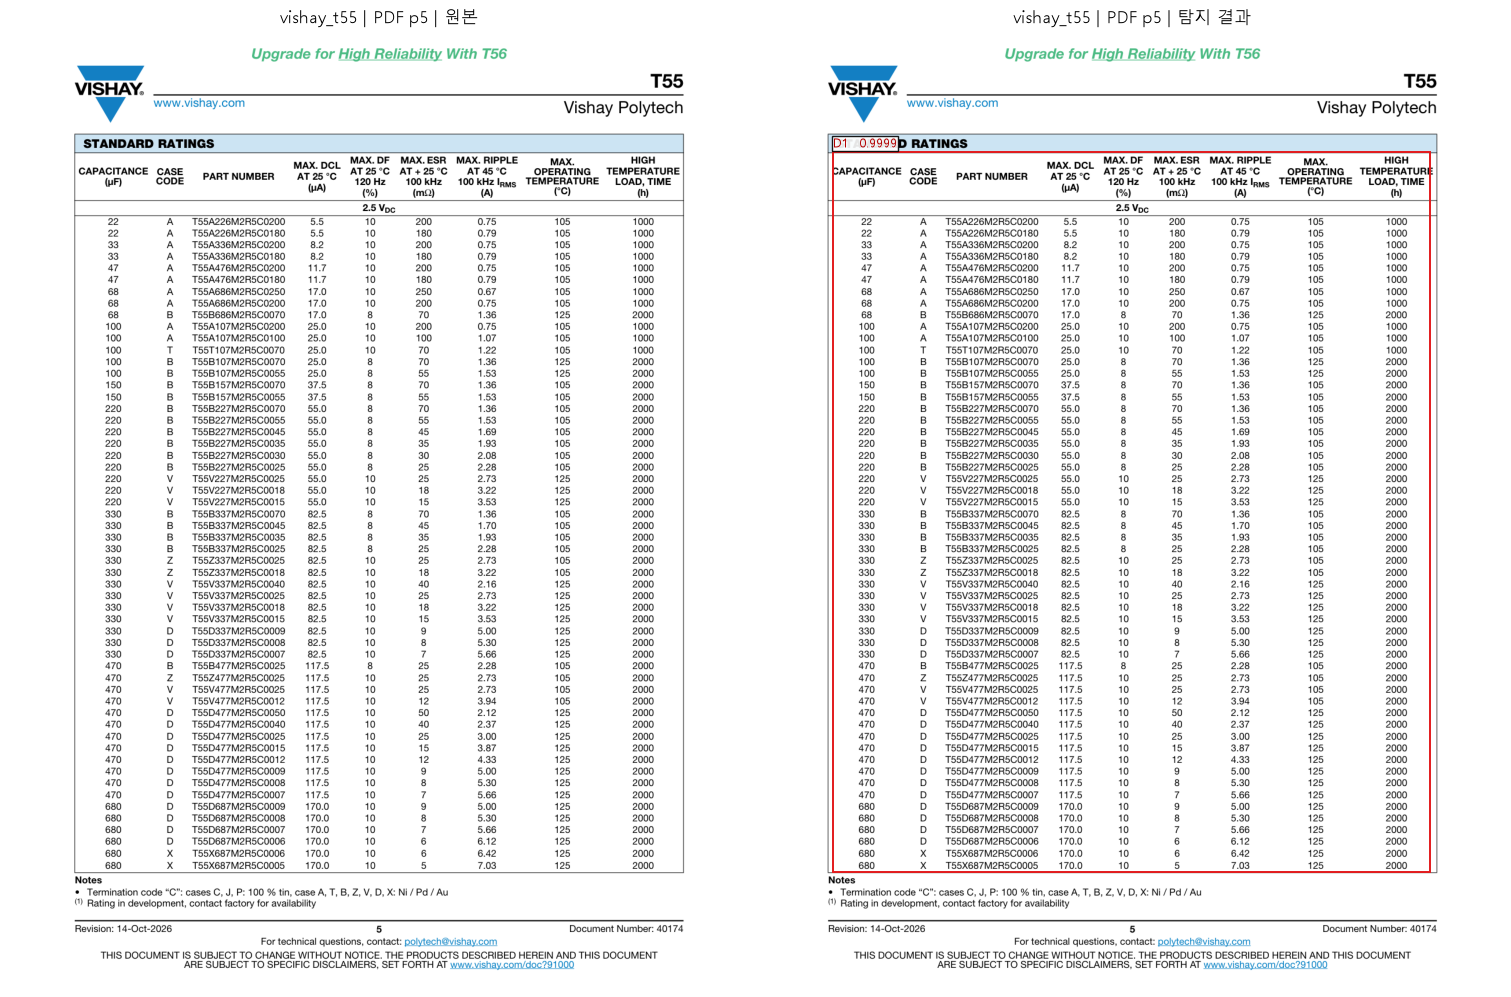

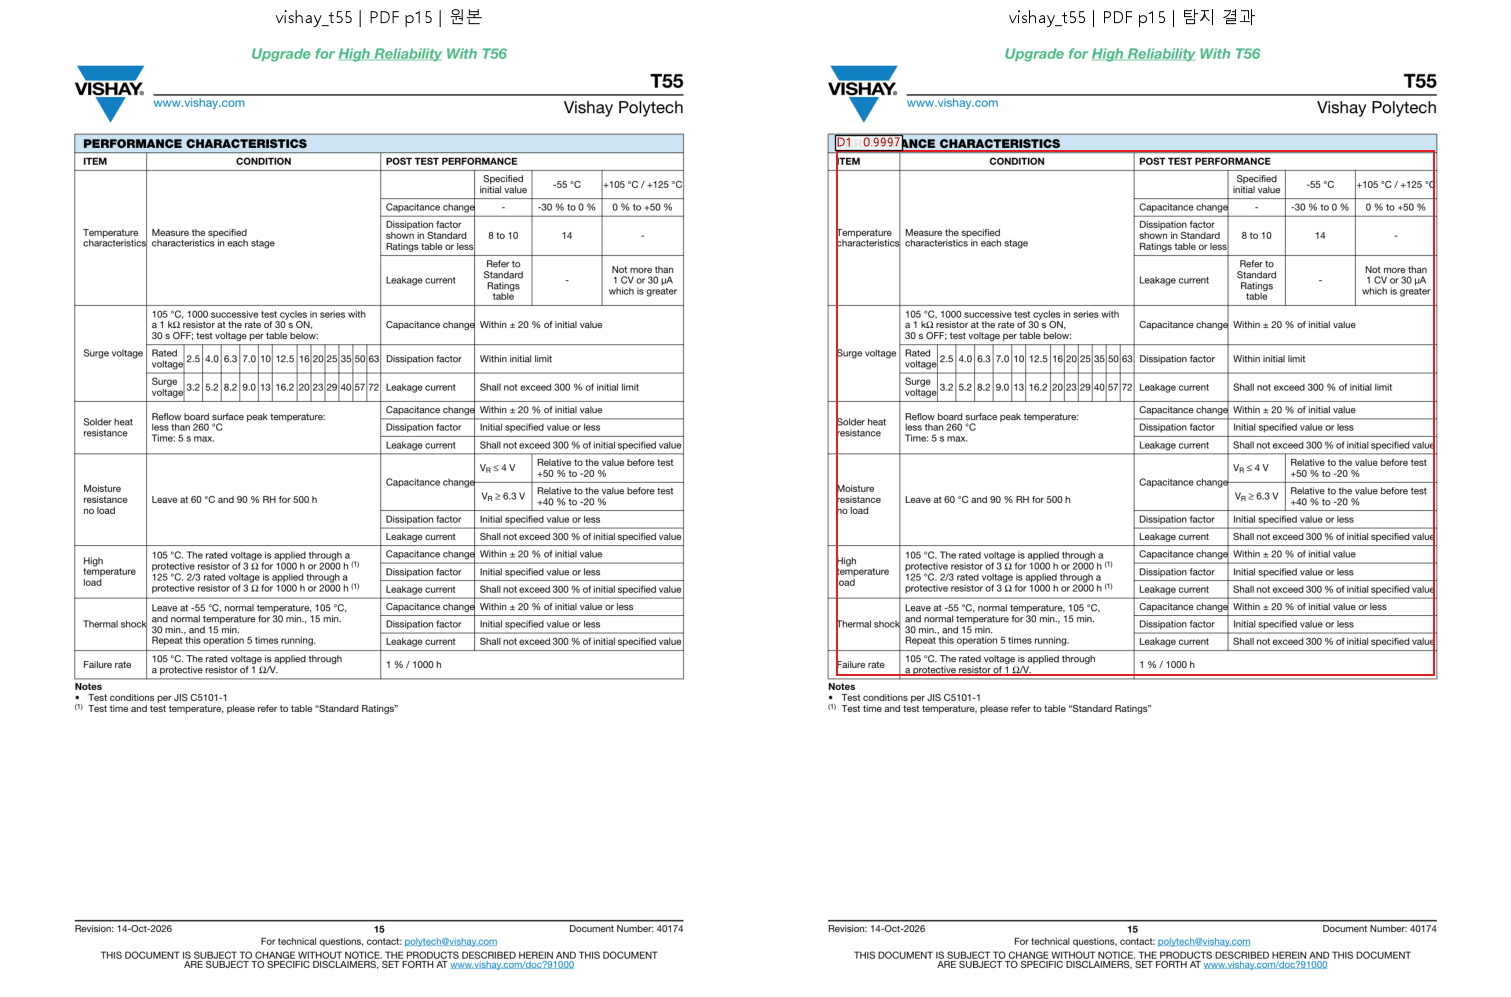

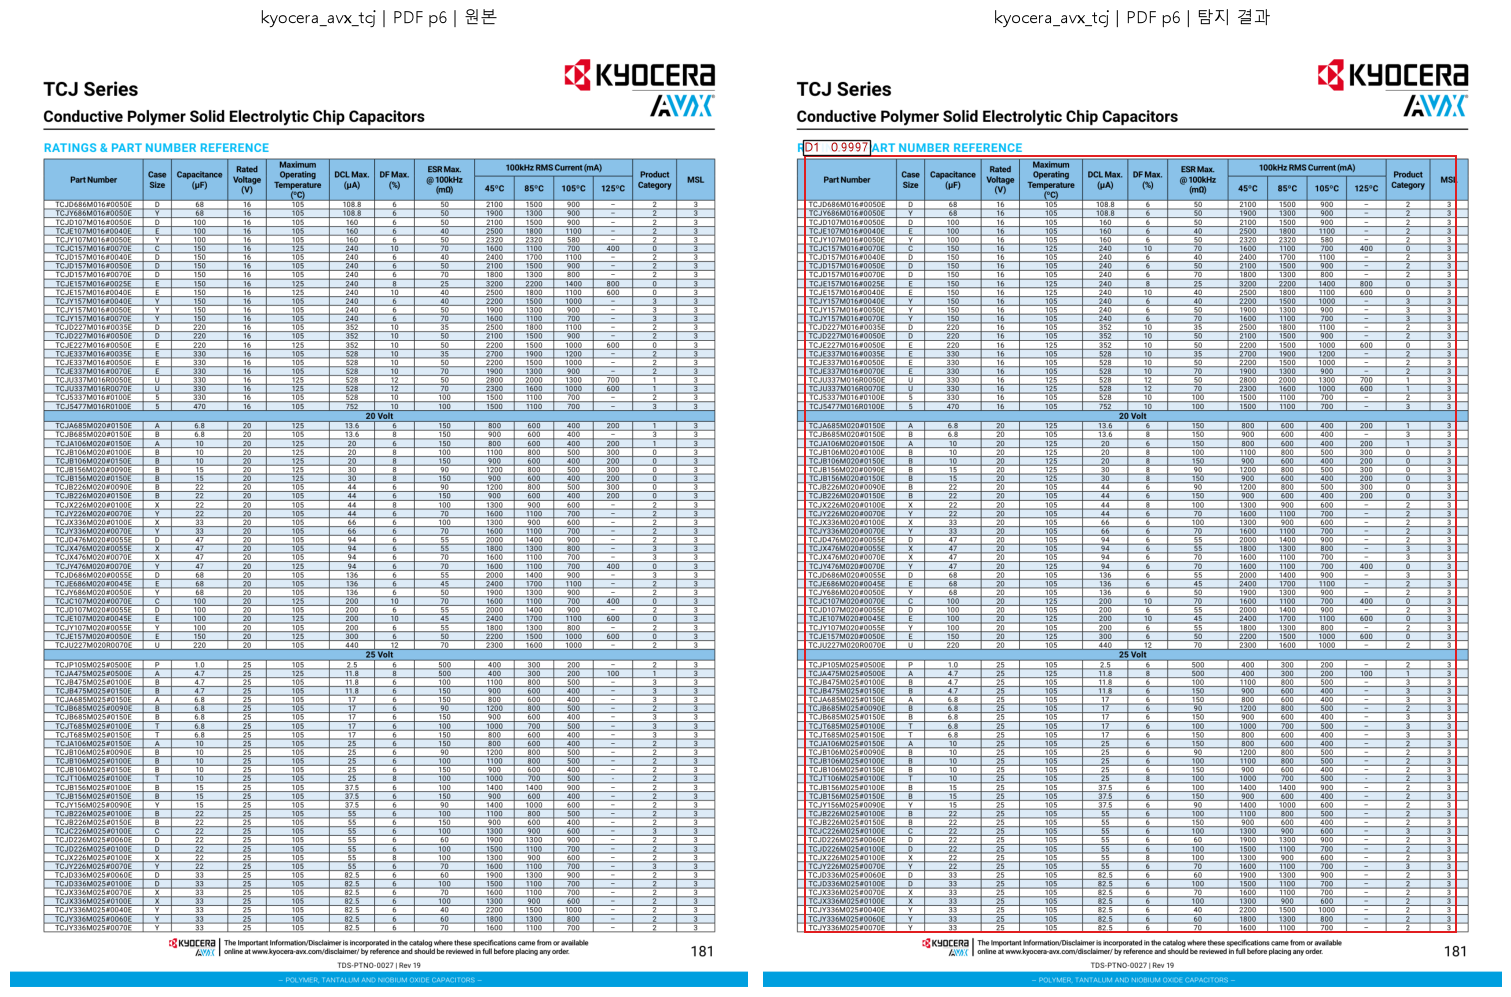

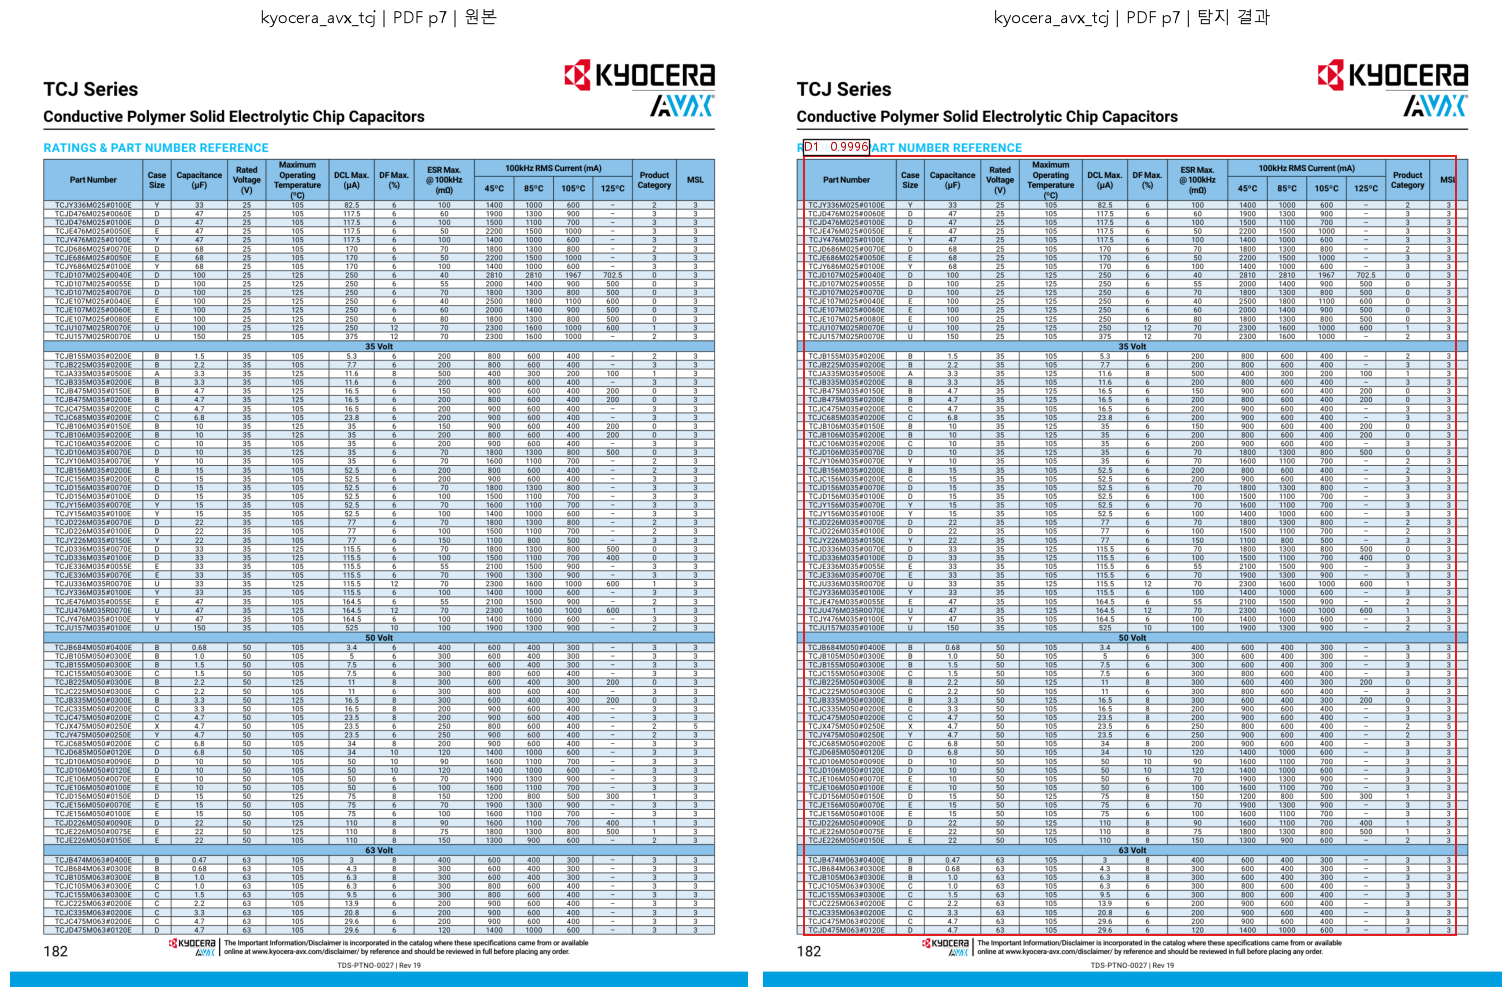

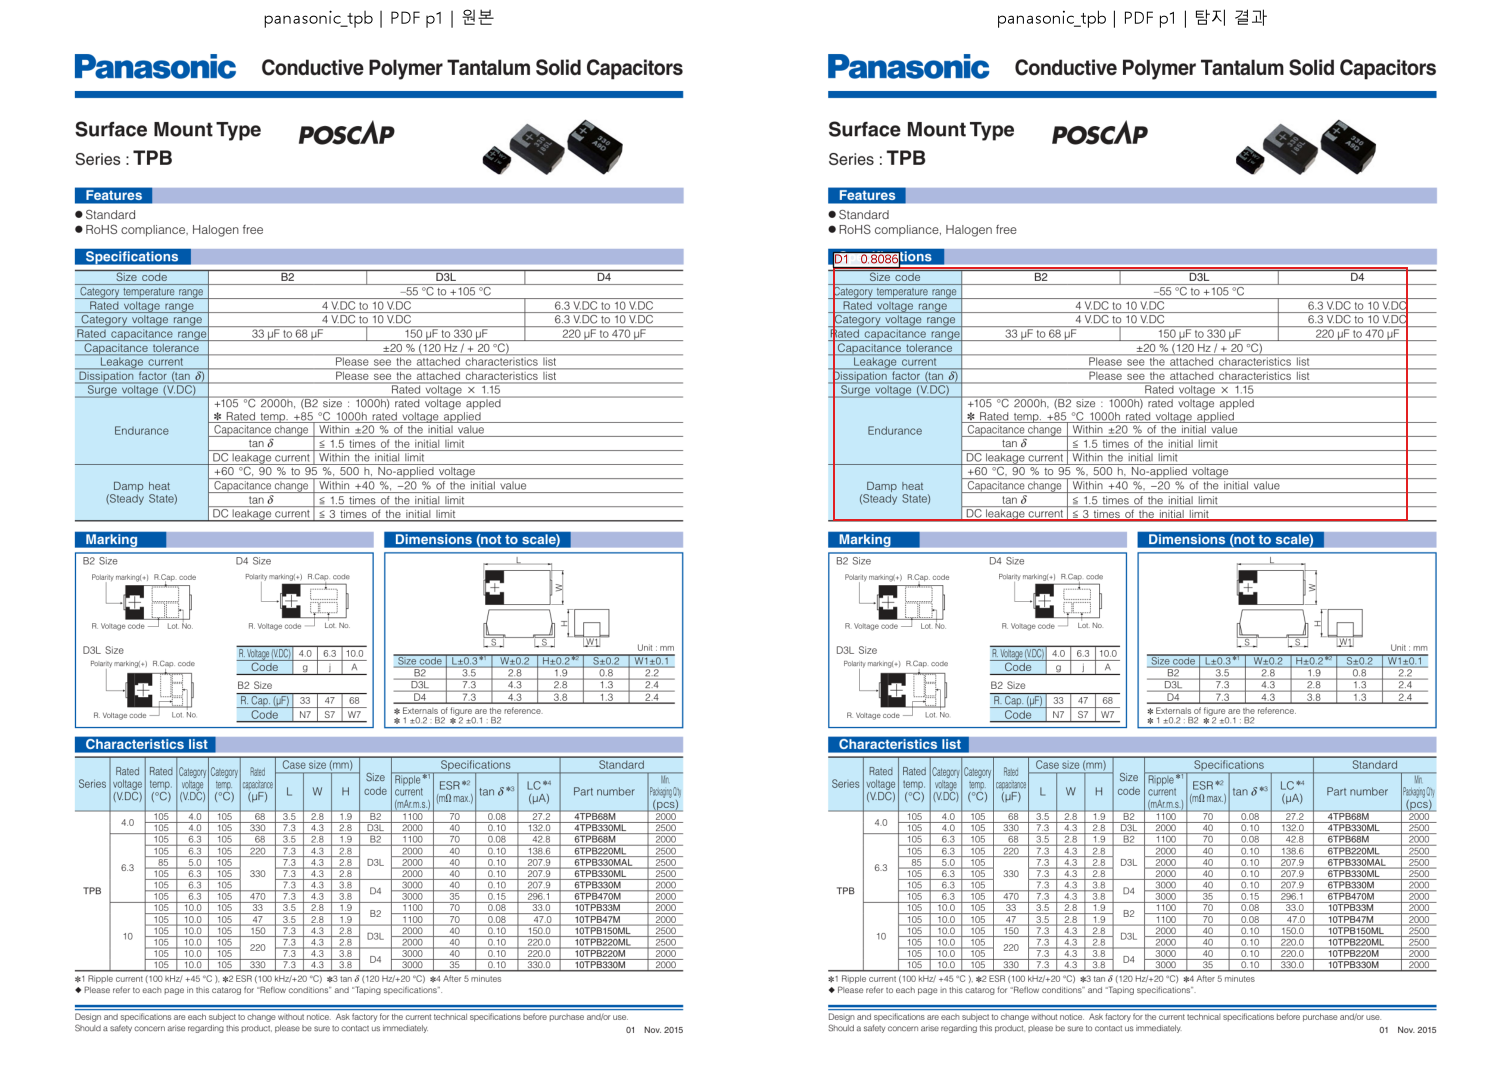

In [6]:
def draw_page(axis, page, overlay):
    """원본과 탐지 영역을 변경 없이 표시함."""
    axis.imshow(page['image'])
    if overlay:
        for detection in page['detections']:
            x0,y0,x1,y1 = detection['bbox']
            axis.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='#e31a1c',linewidth=1.4))
            axis.text(x0,max(0,y0-8),f"D{detection['detection_id']}  {detection['confidence']:.4f}",
                color='#b30000',fontsize=9,bbox={'facecolor':'white','alpha':0.9,'pad':1})
    axis.set_title(f"{page['document_id']} | PDF p{page['page']} | {'탐지 결과' if overlay else '원본'}")
    axis.axis('off')

for page in pages:
    figure, axes = plt.subplots(1,2,figsize=(15,11),layout='constrained')
    draw_page(axes[0],page,False)
    draw_page(axes[1],page,True)
    plt.show()
    plt.close(figure)


In [7]:
REVIEW = [{'document_id': 'vishay_t55', 'page': 5, 'detection_id': 1, 'review_status': 'partial', 'matched_reference_table': 'standard_ratings', 'review_note': '왼쪽 CAPACITANCE 헤더와 오른쪽 HIGH TEMPERATURE 헤더 일부가 상자 밖임. 본문 대부분 포함되나 완전 포함 기준 미충족함', 'expected_bbox': [119.83846282958984, 207.71405029296875, 1150.82421875, 1450.088134765625]}, {'document_id': 'vishay_t55', 'page': 15, 'detection_id': 1, 'review_status': 'partial', 'matched_reference_table': 'performance_characteristics', 'review_note': '왼쪽 ITEM 데이터 글자와 마지막 Failure rate 행 하단 설명 일부가 잘림. 내부 전압 표는 외곽 성능표와 함께 탐지됨', 'expected_bbox': [126.14543914794922, 205.99783325195312, 1157.6846923828125, 1110.2518310546875]}, {'document_id': 'kyocera_avx_tcj', 'page': 6, 'detection_id': 1, 'review_status': 'partial', 'matched_reference_table': 'ratings_reference', 'review_note': '규격표 본문 포함됨. 오른쪽 MSL 헤더 일부가 경계 밖임. 완전 포함 기준 미충족함', 'expected_bbox': [70.6371841430664, 214.6752471923828, 1196.081298828125, 1554.6500244140625]}, {'document_id': 'kyocera_avx_tcj', 'page': 7, 'detection_id': 1, 'review_status': 'partial', 'matched_reference_table': 'ratings_reference', 'review_note': '규격표 본문 포함됨. 오른쪽 MSL 헤더 일부가 경계 밖임. 완전 포함 기준 미충족함', 'expected_bbox': [69.71417236328125, 213.61697387695312, 1195.433837890625, 1559.3033447265625]}, {'document_id': 'panasonic_tpb', 'page': 1, 'detection_id': 1, 'review_status': 'partial', 'matched_reference_table': 'specifications', 'review_note': 'Specifications 좌우 경계 글자와 오른쪽 Size D4 값 일부가 잘림. 치수표·전압 코드표·용량 코드표·Characteristics list는 미탐지함', 'expected_bbox': [118.32150268554688, 396.1536865234375, 1081.222412109375, 818.665283203125]}]
review_map = {(r['document_id'],r['page'],r['detection_id']):r for r in REVIEW}
for page in pages:
    assert len(page['detections']) == 1, '탐지 수 변경되어 수동 재검토 필요함'
    for detection in page['detections']:
        review = review_map[page['document_id'],page['page'],detection['detection_id']]
        assert np.allclose(detection['bbox'],review['expected_bbox'],atol=0.05,rtol=0), '상자 변경되어 수동 재검토 필요함'
display(pd.DataFrame(REVIEW).drop(columns='expected_bbox'))


,document_id,page,detection_id,review_status,matched_reference_table,review_note
0,vishay_t55,5,1,partial,standard_ratings,왼쪽 CAPACITANCE 헤더와 오른쪽 HIGH TEMPERATURE 헤더 일부가...
1,vishay_t55,15,1,partial,performance_characteristics,왼쪽 ITEM 데이터 글자와 마지막 Failure rate 행 하단 설명 일부가 잘...
2,kyocera_avx_tcj,6,1,partial,ratings_reference,규격표 본문 포함됨. 오른쪽 MSL 헤더 일부가 경계 밖임. 완전 포함 기준 미충족함
3,kyocera_avx_tcj,7,1,partial,ratings_reference,규격표 본문 포함됨. 오른쪽 MSL 헤더 일부가 경계 밖임. 완전 포함 기준 미충족함
4,panasonic_tpb,1,1,partial,specifications,Specifications 좌우 경계 글자와 오른쪽 Size D4 값 일부가 잘림....


In [8]:
page_summaries, rows = [], []
for page in pages:
    local_reviews = [review_map[page['document_id'],page['page'],d['detection_id']] for d in page['detections']]
    normal = sum(r['review_status']=='normal' for r in local_reviews)
    partial = sum(r['review_status']=='partial' for r in local_reviews)
    false_positive = sum(r['review_status']=='false_positive' for r in local_reviews)
    actual = len(page['reference_tables'])
    page_summaries.append({'document_id':page['document_id'],'manufacturer':page['manufacturer'],
        'page':page['page'],'actual':actual,'detected':len(page['detections']),
        'normal':normal,'missed':actual-normal,'partial':partial,
        'undetected':actual-normal-partial,'false_positive':false_positive,
        'processing_seconds':page['timing']['processing_seconds'],'render_seconds':page['render_seconds']})
    for row in detection_rows(page['document_id'],MODEL_NAME,page['detections'],page['page_metadata'],page['timing']):
        review = review_map.get((page['document_id'],page['page'],row['detection_id']))
        row.update(manufacturer=page['manufacturer'],threshold=THRESHOLD,
            source_pdf_sha256=pdf_hashes[page['document_id']],weight_sha256=model_record['weight_sha256'],
            device=str(device),reference_table_count=actual,
            review_status=review['review_status'] if review else 'no_detection',
            matched_reference_table=review['matched_reference_table'] if review else '',
            review_note=review['review_note'] if review else '탐지 없음',
            reviewer='Codex 원문 시각 대조',user_review_status='pending')
        rows.append(row)
results = pd.DataFrame(rows)
summary = pd.DataFrame(page_summaries)
counts = ['actual','detected','normal','missed','partial','undetected','false_positive']
by_manufacturer = summary.groupby('manufacturer',sort=False)[counts].sum()
display(summary)
display(by_manufacturer)
totals = summary[counts].sum().astype(int).to_dict()
display({'pdf_count':summary.document_id.nunique(),'page_count':len(summary),**totals,
    'strict_complete_rate':totals['normal']/totals['actual'],
    'processing_seconds_total':summary.processing_seconds.sum(),
    'processing_seconds_mean':summary.processing_seconds.mean(),
    'render_seconds_total':summary.render_seconds.sum()})
assert totals['actual'] == totals['normal']+totals['missed']
assert totals['missed'] == totals['partial']+totals['undetected']
assert totals['detected'] == totals['normal']+totals['partial']+totals['false_positive']
csv_path = ROOT/'results/05_dl_table_detection.csv'
if not csv_path.exists():
    results.to_csv(csv_path,index=False,encoding='utf-8-sig')


,document_id,manufacturer,page,actual,detected,normal,missed,partial,undetected,false_positive,processing_seconds,render_seconds
0,vishay_t55,Vishay,5,1,1,0,1,1,0,0,0.567521,0.077357
1,vishay_t55,Vishay,15,1,1,0,1,1,0,0,0.558308,0.021756
2,kyocera_avx_tcj,KYOCERA AVX,6,1,1,0,1,1,0,0,0.556570,0.059346
3,kyocera_avx_tcj,KYOCERA AVX,7,1,1,0,1,1,0,0,0.532180,0.042482
4,panasonic_tpb,Panasonic,1,5,1,0,5,1,4,0,0.585783,0.041021


,actual,detected,normal,missed,partial,undetected,false_positive
manufacturer,,,,,,,
Vishay,2,2,0,2,2,0,0
KYOCERA AVX,2,2,0,2,2,0,0
Panasonic,5,1,0,5,1,4,0


{'pdf_count': 3,
 'page_count': 5,
 'actual': 9,
 'detected': 5,
 'normal': 0,
 'missed': 9,
 'partial': 5,
 'undetected': 4,
 'false_positive': 0,
 'strict_complete_rate': 0.0,
 'processing_seconds_total': np.float64(2.8003628000005847),
 'processing_seconds_mean': np.float64(0.560072560000117),
 'render_seconds_total': np.float64(0.24196169999959238)}

## 결과 해석
- 총 9개 실제 표 중 5개에 대응하는 상자 탐지됨. 5개 모두 글자 경계 잘림이 있는 부분 탐지임
- 엄격한 완전 포함 기준 정상 0개, 누락 9개임. 누락의 내역은 부분 탐지 5개와 완전 미탐지 4개임. 오탐 0개임
- 완전 포함률 0/9임. 표 존재 위치를 찾는 능력과 추출에 바로 사용할 수 있는 완전한 crop 품질을 구분해야 함
- Vishay: 긴 규격표와 중첩 성능표의 큰 영역 찾았으나 가장자리 글자 잘림 발생함
- KYOCERA AVX: 긴 규격표 본문은 포함했으나 MSL 헤더 경계 잘림 발생함. 높은 confidence가 완전한 경계 품질을 보장하지 않음
- Panasonic: Specifications 일부 탐지됨. 작은 코드표 2개·치수표·큰 Characteristics list 모두 미탐지함. 작은 표만의 문제로 단정 불가함
- 이번 5페이지에서는 도면·설명문을 표로 오탐한 사례와 별도 설명문까지 크게 합친 사례 확인되지 않음. T55 p15 셀 내부 설명문은 표의 일부임
- 원본 150 DPI여도 전처리 후 모델 입력 최대 변은 약 800픽셀임. 작은 글자·다중 배치의 정보 감소 가능성 있으나 DPI 영향 비교는 미실시함
- 미검증: 다른 임계값, 해상도, padding, 구조 인식, 표 내부 텍스트, P/N 연결, 평가용 PDF, GPU 실행임
- 활용 판단: 후보 영역 제안 용도로 실행 가능함. LLM 입력 자동 crop에는 현재 경계 잘림·미탐지 보완 및 검토 필요함. 이번 단계에서 연계 구현하지 않음
- 소수 개발 표본의 Codex 수동 검토 결과임. 독립 사용자 검토·정식 정답 좌표·일반화 성능 평가 완료를 의미하지 않음


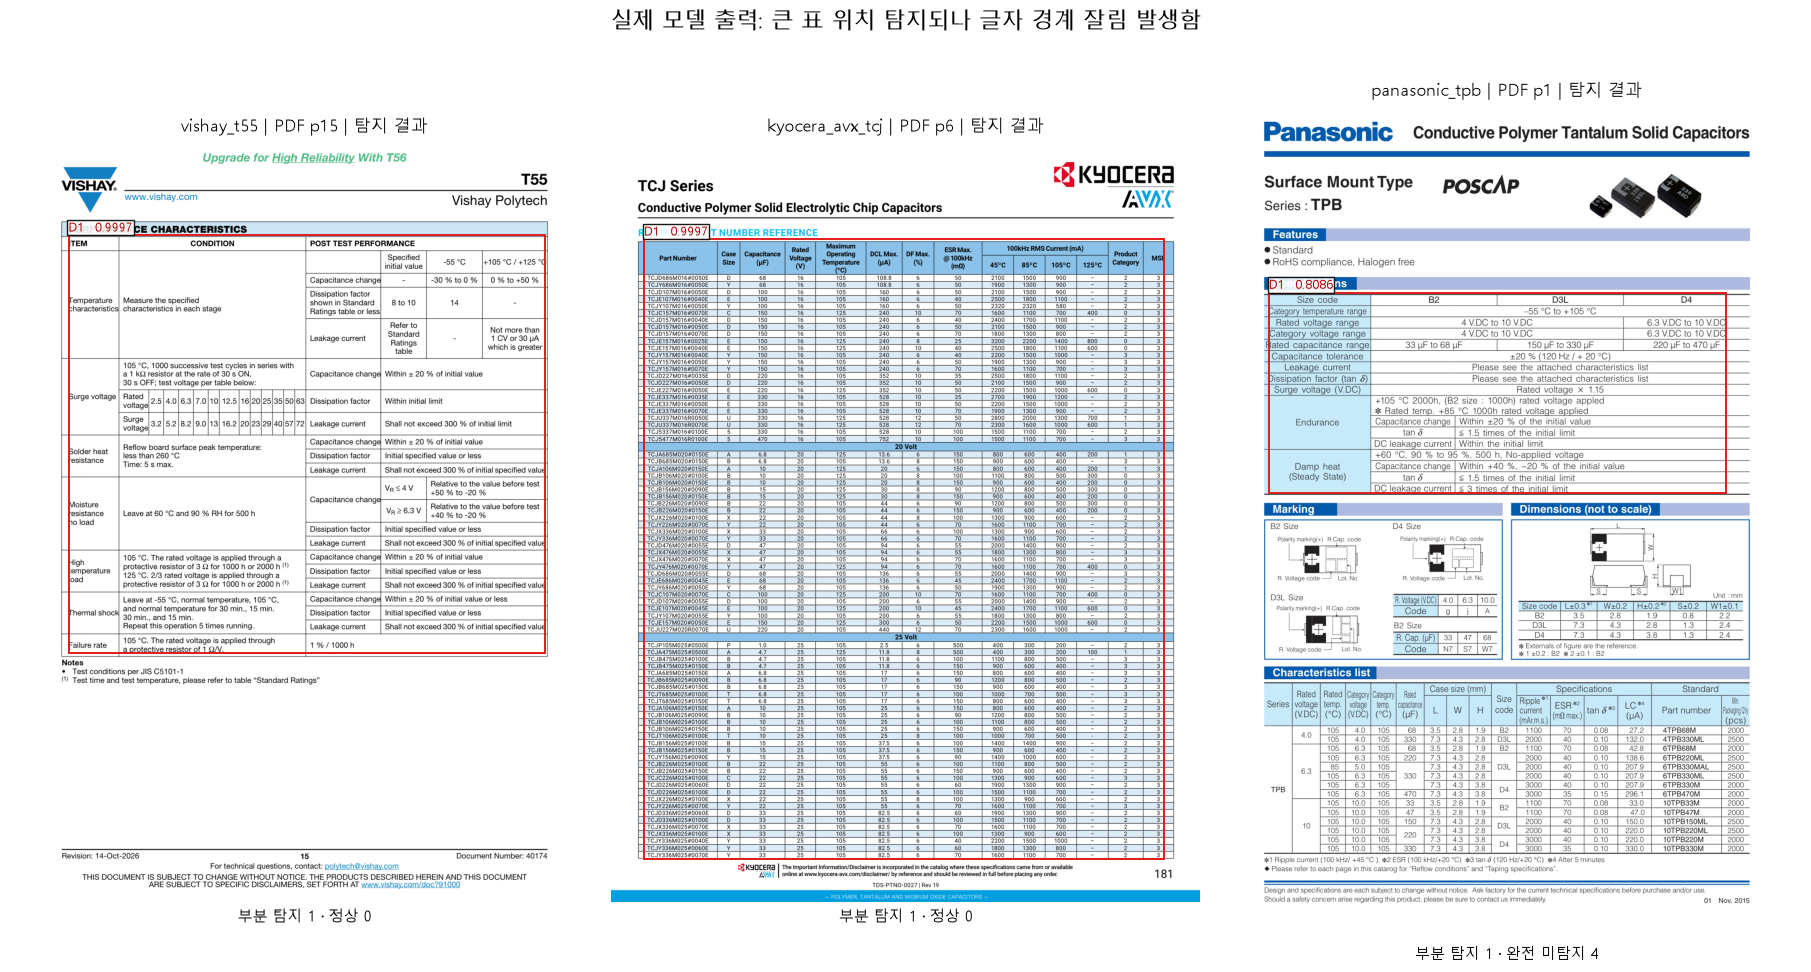

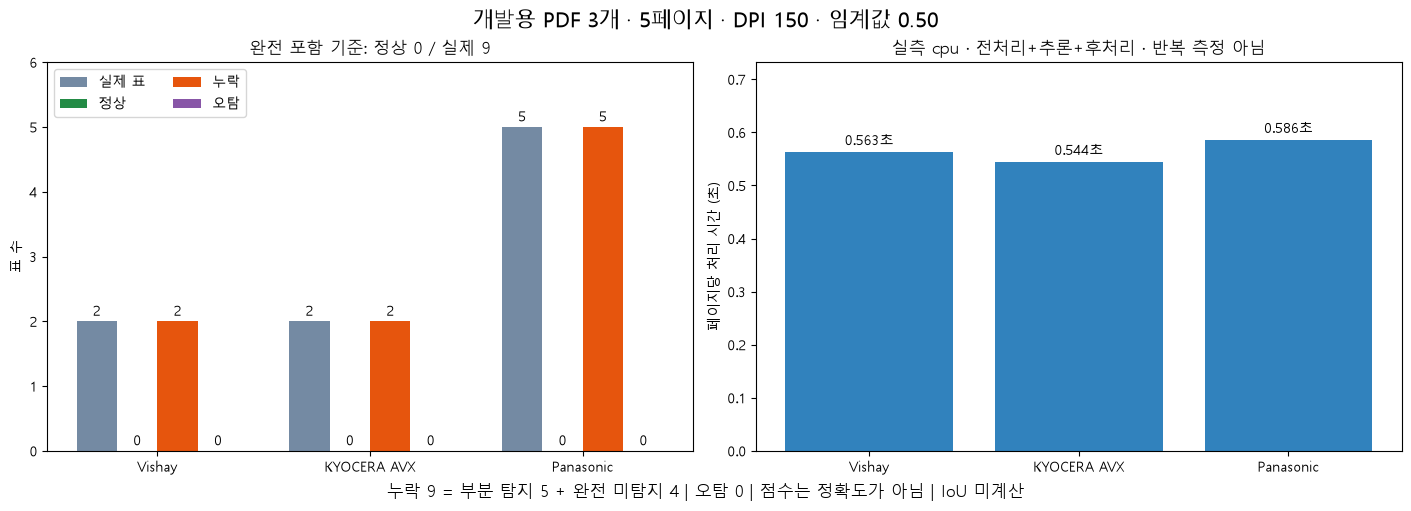

In [9]:
example_pages = [pages[1],pages[2],pages[4]]
figure, axes = plt.subplots(1,3,figsize=(18,10),layout='constrained')
for axis,page in zip(axes,example_pages):
    draw_page(axis,page,True)
    detail = '부분 탐지 1 · 완전 미탐지 4' if page['document_id']=='panasonic_tpb' else '부분 탐지 1 · 정상 0'
    axis.set_xlabel(detail)
    axis.text(0.5,-0.025,detail,transform=axis.transAxes,ha='center',fontsize=11)
figure.suptitle('실제 모델 출력: 큰 표 위치 탐지되나 글자 경계 잘림 발생함',fontsize=16)
if not (ROOT/'outputs/05_dl_table_detection_examples.png').exists():
    figure.savefig(ROOT/'outputs/05_dl_table_detection_examples.png',dpi=180,bbox_inches='tight')
plt.show()
plt.close(figure)

figure, axes = plt.subplots(1,2,figsize=(14,5),layout='constrained')
labels = ['실제 표','정상','누락','오탐']
for offset,(column,label,color) in enumerate(zip(['actual','normal','missed','false_positive'],labels,
                                                ['#748aa3','#238b45','#e6550d','#8856a7'])):
    bars = axes[0].bar(np.arange(len(by_manufacturer))+(offset-1.5)*0.19,
        by_manufacturer[column],width=0.19,label=label,color=color)
    axes[0].bar_label(bars,padding=2)
axes[0].set_xticks(np.arange(len(by_manufacturer)),by_manufacturer.index)
axes[0].set_ylim(0,6)
axes[0].set_ylabel('표 수')
axes[0].legend(ncols=2)
axes[0].set_title('완전 포함 기준: 정상 0 / 실제 9')
timing_by_manufacturer = summary.groupby('manufacturer',sort=False).processing_seconds.mean()
bars = axes[1].bar(timing_by_manufacturer.index,timing_by_manufacturer,color='#3182bd')
axes[1].bar_label(bars,fmt='%.3f초',padding=3)
axes[1].set_ylim(0,max(timing_by_manufacturer)*1.25)
axes[1].set_ylabel('페이지당 처리 시간 (초)')
axes[1].set_title(f'실측 {device} · 전처리+추론+후처리 · 반복 측정 아님')
figure.suptitle('개발용 PDF 3개 · 5페이지 · DPI 150 · 임계값 0.50',fontsize=15)
figure.supxlabel('누락 9 = 부분 탐지 5 + 완전 미탐지 4 | 오탐 0 | 점수는 정확도가 아님 | IoU 미계산')
if not (ROOT/'outputs/05_dl_detection_summary.png').exists():
    figure.savefig(ROOT/'outputs/05_dl_detection_summary.png',dpi=180,bbox_inches='tight')
plt.show()
plt.close(figure)


## 검증 및 경고
- CSV 재읽기·탐지 수·좌표 유효성·PDF 좌표 왕복·모델 버전·PNG 저장 확인함
- 무탐지 분기는 별도의 함수 검증용 빈 입력으로 확인함. 실제 모델의 무탐지 페이지는 이번 실행에 없음
- Transformers 5의 API 차이에 따라 backend="pil" 사용함. 오래된 use_pretrained_backbone 로드 인자 제거함. resnet18 구성 확인함
- 가중치 로드에서 num_batches_tracked 3개가 unexpected로 보고됨. Frozen BatchNorm의 학습 카운터이며 추론 파라미터 아님. 누락·크기 불일치·오류 키 없음 확인함
- Windows 캐시 symlink 미지원 및 비인증 Hugging Face 요청 경고는 최초 확보 시 발생함. 캐시 다운로드와 실측 추론 성공함
- 현재 CPU용 PyTorch임. CUDA 사용 불가 확인함. 물리 GPU 유무는 관리 조회 권한 제한으로 확정하지 않음
- 사용자 검토 후 다음 단계 승인 대기함


In [10]:
loaded = pd.read_csv(csv_path,encoding='utf-8-sig')
required = {'document_id','page','model_name','image_width','image_height','detection_count','confidence','bbox','processing_seconds'}
assert required <= set(loaded.columns)
assert len(loaded)==len(results)==totals['detected']
assert len(loaded[['document_id','page']].drop_duplicates())==5
assert loaded.groupby(['document_id','page']).size().tolist()==[1]*5
for page in pages:
    meta = page['page_metadata']
    for detection in page['detections']:
        x0,y0,x1,y1 = detection['bbox']
        assert 0<=x0<x1<=meta['image_width'] and 0<=y0<y1<=meta['image_height']
        assert THRESHOLD <= detection['confidence'] <= 1
        box_pdf = image_bbox_to_pdf(detection['bbox'],meta)
        left,top,right,bottom = meta['pdf_rect']
        back = [(box_pdf[0]-left)*meta['image_width']/(right-left),
            (box_pdf[1]-top)*meta['image_height']/(bottom-top),
            (box_pdf[2]-left)*meta['image_width']/(right-left),
            (box_pdf[3]-top)*meta['image_height']/(bottom-top)]
        assert np.allclose(back,detection['bbox'])
    empty = detection_rows(page['document_id'],MODEL_NAME,[],meta,page['timing'])
    assert len(empty)==1 and empty[0]['detection_count']==0 and empty[0]['confidence'] is None
    assert empty[0]['bbox']=='' and empty[0]['detection_id']==0
for document_id,original_hash in pdf_hashes.items():
    assert hashlib.sha256((ROOT/'data/datasheets'/manifest.loc[document_id,'filename']).read_bytes()).hexdigest()==original_hash
assert not (ROOT/'README.md').exists()
assert all(path.suffix.lower()=='.png' for path in (ROOT/'outputs').rglob('*') if path.is_file())
for filename in ['05_dl_table_detection_examples.png','05_dl_detection_summary.png']:
    with Image.open(ROOT/'outputs'/filename) as image:
        assert image.format=='PNG'
        image.verify()
audit = {'status':'passed','pdf_count':3,'page_count':5,**totals,
    'csv_rows':len(loaded),'processing_seconds_total':float(summary.processing_seconds.sum()),
    'processing_seconds_mean':float(summary.processing_seconds.mean()),
    'render_seconds_total':float(summary.render_seconds.sum()),'load_seconds':load_seconds,
    'device':str(device),'revision':MODEL_REVISION,'weight_sha256':model_record['weight_sha256']}
display(audit)


{'status': 'passed',
 'pdf_count': 3,
 'page_count': 5,
 'actual': 9,
 'detected': 5,
 'normal': 0,
 'missed': 9,
 'partial': 5,
 'undetected': 4,
 'false_positive': 0,
 'csv_rows': 5,
 'processing_seconds_total': 2.8003628000005847,
 'processing_seconds_mean': 0.560072560000117,
 'render_seconds_total': 0.24196169999959238,
 'load_seconds': 0.9067087000003085,
 'device': 'cpu',
 'revision': '2357cbe2b5a5d1c03e54f32764f06058933b65ab',
 'weight_sha256': '8f1aa73170102c038d40155e2734b343bf07e0fe12594228a8590943b01dccf7'}

## 보완 실험: 표 경계 여백과 신뢰도 임계값
- 최초 실험의 결과·이미지 보존함. 같은 개발 PDF 3개, 물리 페이지 5개, 150 DPI, 동일 가중치로 보완함
- 기획서 v3.1 §3·§4.1에 따라 탐지 영역과 PDF 원문 문자·좌표 결합을 시험함. LLM 호출·P/N 규격 연결·평가용 PDF는 이번 범위 아님
- 페이지당 1회 추론 후 0.30 후보에서 0.40·0.50을 필터링함. 각 후보의 너비·높이 × 여백 비율만큼 좌우·상하 **각각** 확장하고 이미지 경계로 제한함
- 페이지 원문에서 표·헤더·본문 범위를 시각 대조해 지정함. 고정된 PDF 좌표 영역에서 헤더와 본문 단어 상자가 모두 포함될 때 정상으로 계산함. 외곽 여백·선은 제외함
- 정상은 글자 전체 포함을 뜻함. 별도 표·절·도면·페이지 머리말·꼬리말·면책문 혼입은 별도 기록함. 같은 표 제목과 관련 각주는 허용하되 외부 단어 수에 기록함
- PDF 단어 상자는 글리프 외곽보다 보수적일 수 있음. P/N·규격값 포함은 행 본문 단어 전체의 공간적 포함이며 값의 해석·연결 검증이 아님
- PDF 물리 페이지 및 좌상단 원점 point 좌표 유지함. 수동 검토 영역은 IoU용 정답 박스가 아님

In [11]:
import pymupdf
from table_detection import expand_table_bbox, extract_pdf_page_text

thresholds = (.30, .40, .50)
padding_ratios = (0., .02, .05, .10)

# 표 내용 범위, 헤더와 본문 분리 기준, P/N 열 존재 여부를 원문 대조로 지정함
reference_windows = {
    ('vishay_t55',5): {'standard_ratings': ((50,101,560,698),142,True)},
    ('vishay_t55',15): {'performance_characteristics': ((50,100,560,537),116,False)},
    ('kyocera_avx_tcj',6): {'ratings_reference': ((25,103,590,748),138,True)},
    ('kyocera_avx_tcj',7): {'ratings_reference': ((25,103,590,750),139,True)},
    ('panasonic_tpb',1): {'specifications': ((50,190,543,398),205,False),
        'dimensions': ((309,502,537,542),513,False),
        'voltage_code': ((182,497,288,519),508,False),
        'capacitance_code': ((182,535,288,557),546,False),
        'characteristics_list': ((50,585,544,758),628,True)}
}
# 같은 표 제목과 관련 각주는 별도 표·본문 혼입에서 제외함
related_text_bands = {
    ('vishay_t55',5): [(84,100),(698,729)],
    ('vishay_t55',15): [(84,100),(537,568)],
    ('kyocera_avx_tcj',6): [(87,103)],
    ('kyocera_avx_tcj',7): [(87,103)],
    ('panasonic_tpb',1): [(173,189)]
}

def word_center(word):
    """단어의 PDF 좌표 중심을 반환함."""
    return (word[0]+word[2])/2, (word[1]+word[3])/2

def in_window(word, bounds):
    """수동 확인 범위에 단어 중심이 속하는지 확인함."""
    x,y = word_center(word)
    return bounds[0] <= x <= bounds[2] and bounds[1] <= y <= bounds[3]

def overlaps_word(word, bounds):
    """본문의 양의 면적 교차를 확인함. 0.25pt 이내 접촉은 제외함."""
    return all(min(word[i+2],bounds[i+2])-max(word[i],bounds[i]) > .25 for i in (0,1))

page_index = {(p['document_id'],p['page']):p for p in pages}
refinement_candidates, refinement_times, page_source = {}, {}, {}
for key, page in page_index.items():
    assert set(reference_windows[key]) == set(page['reference_tables'])
    pdf_path = ROOT/'data/datasheets'/manifest.loc[key[0],'filename']
    refinement_candidates[key], refinement_times[key] = detect_tables(
        page['image'],processor,model,device,threshold=min(thresholds))
    page_source[key] = extract_pdf_page_text(pdf_path,key[1])
    high = [d for d in refinement_candidates[key] if d['confidence'] > .50]
    assert len(high) == len(page['detections'])
    assert all(np.allclose(a['bbox'],b['bbox'],atol=.05,rtol=0)
               and abs(a['confidence']-b['confidence'])<1e-6
               for a,b in zip(high,page['detections']))
display(pd.DataFrame([{'document_id':key[0],'page':key[1],
    'model_input_width':t['model_input_width'],'model_input_height':t['model_input_height'],
    'inference_seconds':t['inference_seconds'],'candidates_at_030':len(refinement_candidates[key])}
    for key,t in refinement_times.items()]))

,document_id,page,model_input_width,model_input_height,inference_seconds,candidates_at_030
0,vishay_t55,5,618,799,0.484790,1
1,vishay_t55,15,618,799,0.408375,1
2,kyocera_avx_tcj,6,618,799,0.434123,1
3,kyocera_avx_tcj,7,618,799,0.430439,1
4,panasonic_tpb,1,565,800,0.421453,1


### 동일 표 매칭 및 조건별 판정
- 원문과 탐지 상자를 직접 대조한 결과, 각 페이지 첫 번째 상자가 아래 표에 대응함. 나머지 TPB 표 4개와 매칭된 상자 없음
- 실제 후보가 바뀌면 과거 매칭을 재사용하지 않고 검토 오류로 중단함. 미탐지와 부분 탐지는 정상 건수에서 제외함
- 표 밖 글자 혼입은 대조한 구간과 원문 단어 좌표 교차로 확인함. 표 제목 및 관련 각주가 상자 가장자리에 일부 포함될 수 있으므로 별도 본문 입력 유지 필요함

In [12]:
manual_matches = {
    ('vishay_t55',5): {1:'standard_ratings'},
    ('vishay_t55',15): {1:'performance_characteristics'},
    ('kyocera_avx_tcj',6): {1:'ratings_reference'},
    ('kyocera_avx_tcj',7): {1:'ratings_reference'},
    ('panasonic_tpb',1): {1:'specifications'}
}
refinement_rows = []
for key,page in page_index.items():
    doc_id,page_number = key
    meta = page['page_metadata']
    words = page_source[key]['page_words']
    candidates = refinement_candidates[key]
    match = manual_matches[key]
    assert {d['detection_id'] for d in candidates} == set(match), '탐지 후보 변경됨: 원문 재대조 필요함'
    for threshold in thresholds:
        active = {match[d['detection_id']]:d for d in candidates if d['confidence'] > threshold}
        for padding in padding_ratios:
            for table_id,(window,header_end,has_pn) in reference_windows[key].items():
                target = [w for w in words if in_window(w,window)]
                head = [w for w in target if word_center(w)[1] < header_end]
                body = [w for w in target if word_center(w)[1] >= header_end]
                assert head and body
                detection = active.get(table_id)
                row = dict(document_id=doc_id,page=page_number,table_id=table_id,
                    threshold=threshold,padding_ratio=padding,original_bbox=None,expanded_bbox=None,
                    confidence=None,detection_status='undetected',header_included=False,
                    pn_values_included=False if has_pn else None,unrelated_content_included=None,
                    manual_review_status='codex_source_reviewed',spec_values_included=False,
                    original_bbox_pdf=None,expanded_bbox_pdf=None,reference_window_pdf=json.dumps(window),
                    candidate_id=None,source_pdf_sha256=pdf_hashes[doc_id],model_revision=MODEL_REVISION,
                    target_words=len(target),missing_target_words=len(target),outside_target_words=None,
                    unrelated_words=None,other_table_included=None,unrelated_sample='',
                    result_origin='no_matching_candidate',user_review_status='pending')
                if detection:
                    original = detection['bbox']
                    expanded = expand_table_bbox(original,meta['image_width'],meta['image_height'],padding)
                    assert expand_table_bbox(original,meta['image_width'],meta['image_height'],0) == original
                    original_pdf = image_bbox_to_pdf(original,meta)
                    expanded_pdf = image_bbox_to_pdf(expanded,meta)
                    crop = pymupdf.Rect(expanded_pdf)
                    header_included = all(crop.contains(pymupdf.Rect(w[:4])) for w in head)
                    body_included = all(crop.contains(pymupdf.Rect(w[:4])) for w in body)
                    missing = sum(not crop.contains(pymupdf.Rect(w[:4])) for w in target)
                    outside = [w for w in words if not in_window(w,window) and overlaps_word(w,expanded_pdf)]
                    other_table = any(in_window(w,other_window) for w in outside
                        for other_id,(other_window,_,_) in reference_windows[key].items() if other_id!=table_id)
                    unrelated = [w for w in outside
                        if not any(lo <= word_center(w)[1] < hi for lo,hi in related_text_bands[key])]
                    row.update(original_bbox=json.dumps(original),expanded_bbox=json.dumps(expanded),
                        confidence=detection['confidence'],detection_status='normal' if missing==0 else 'partial',
                        header_included=header_included,pn_values_included=body_included if has_pn else None,
                        unrelated_content_included=bool(unrelated or other_table),spec_values_included=body_included,
                        original_bbox_pdf=json.dumps(original_pdf),expanded_bbox_pdf=json.dumps(expanded_pdf),
                        candidate_id=detection['detection_id'],missing_target_words=missing,
                        outside_target_words=len(outside),unrelated_words=len(unrelated),
                        other_table_included=other_table,unrelated_sample=' '.join(w[4] for w in unrelated[:12]),
                        result_origin='padding_recovery' if missing==0 and padding>0 else 'original_candidate')
                refinement_rows.append(row)

refinement = pd.DataFrame(refinement_rows)
condition_counts = refinement.groupby(['threshold','padding_ratio','detection_status']).size().unstack(fill_value=0)
condition_counts = condition_counts.reindex(columns=['normal','partial','undetected','false_positive'],fill_value=0)
condition_counts['candidates'] = [sum(d['confidence']>t for ds in refinement_candidates.values() for d in ds)
    for t,_ in condition_counts.index]
assert (condition_counts.candidates == condition_counts.normal+condition_counts.partial+condition_counts.false_positive).all()
condition_counts['actual'] = condition_counts.normal+condition_counts.partial+condition_counts.undetected
condition_counts['normal_ratio'] = condition_counts.normal/condition_counts.actual
condition_counts['unrelated'] = refinement.assign(mixed=refinement.unrelated_content_included.eq(True)).groupby(
    ['threshold','padding_ratio']).mixed.sum()
condition_counts['clean_normal'] = refinement.assign(clean=refinement.detection_status.eq('normal') &
    refinement.unrelated_content_included.eq(False)).groupby(['threshold','padding_ratio']).clean.sum()
assert condition_counts.loc[(.50,0.),['normal','partial','undetected','false_positive']].to_list()==[0,5,4,0]
display(condition_counts)
display(refinement.query('threshold == 0.5')[['document_id','page','table_id','padding_ratio',
    'detection_status','header_included','pn_values_included','spec_values_included',
    'missing_target_words','outside_target_words','unrelated_words','unrelated_sample']])

detection_status         normal  partial  undetected  false_positive  \
threshold padding_ratio                                                
0.3       0.00                0        5           4               0   
          0.02                5        0           4               0   
          0.05                5        0           4               0   
          0.10                5        0           4               0   
0.4       0.00                0        5           4               0   
          0.02                5        0           4               0   
          0.05                5        0           4               0   
          0.10                5        0           4               0   
0.5       0.00                0        5           4               0   
          0.02                5        0           4               0   
          0.05                5        0           4               0   
          0.10                5        0           4               0   

detection_status         candidates  actual  normal_ratio  unrelated  \
threshold padding_ratio                                                
0.3       0.00                    5       9      0.000000          0   
          0.02                    5       9      0.555556          2   
          0.05                    5       9      0.555556          3   
          0.10                    5       9      0.555556          5   
0.4       0.00                    5       9      0.000000          0   
          0.02                    5       9      0.555556          2   
          0.05                    5       9      0.555556          3   
          0.10                    5       9      0.555556          5   
0.5       0.00                    5       9      0.000000          0   
          0.02                    5       9      0.555556          2   
          0.05                    5       9      0.555556          3   
          0.10                    5       9      0.555556          5   

detection_status         clean_normal  
threshold padding_ratio                
0.3       0.00                      0  
          0.02                      3  
          0.05                      2  
          0.10                      0  
0.4       0.00                      0  
          0.02                      3  
          0.05                      2  
          0.10                      0  
0.5       0.00                      0  
          0.02                      3  
          0.05                      2  
          0.10                      0

,document_id,page,table_id,padding_ratio,detection_status,header_included,pn_values_included,spec_values_included,missing_target_words,outside_target_words,unrelated_words,unrelated_sample
8,vishay_t55,5,standard_ratings,0.00,partial,False,False,False,11,0.0,0.0,
9,vishay_t55,5,standard_ratings,0.02,normal,True,True,True,0,3.0,0.0,
10,vishay_t55,5,standard_ratings,0.05,normal,True,True,True,0,37.0,2.0,Vishay Polytech
11,vishay_t55,5,standard_ratings,0.10,normal,True,True,True,0,50.0,15.0,T55 www.vishay.com Vishay Polytech Revision: 1...
20,vishay_t55,15,performance_characteristics,0.00,partial,True,None,False,11,0.0,0.0,
21,vishay_t55,15,performance_characteristics,0.02,normal,True,None,True,0,3.0,0.0,
22,vishay_t55,15,performance_characteristics,0.05,normal,True,None,True,0,9.0,0.0,
23,vishay_t55,15,performance_characteristics,0.10,normal,True,None,True,0,24.0,3.0,www.vishay.com Vishay Polytech
32,kyocera_avx_tcj,6,ratings_reference,0.00,partial,False,False,False,15,0.0,0.0,
33,kyocera_avx_tcj,6,ratings_reference,0.02,normal,True,True,True,0,36.0,31.0,The Important Information/Disclaimer is incorp...


### PDF 원문 연계 및 미탐지 원인
- 03 Notebook에서 사용한 PyMuPDF get_text·pdfplumber extract_text 방식 재사용함. 이번에는 전체 페이지와 2% 보정 영역을 별도 반환함
- 각 도구의 원문을 대조하고 대표 토큰 및 좌표를 확인함. 두 도구의 읽기 순서와 기호는 다를 수 있으며 파싱 결과가 표 셀이나 P/N 연결을 검증하지 않음
- TPB의 네 표는 0.30에서도 대응 상자 없음. 작은 코드표와 도면 혼합 배치, 전처리 축소가 후보 원인이지만 큰 Characteristics list도 미탐지되므로 작은 크기만으로 설명할 수 없음. 설정별 원인 분리 실험 미수행임
- TPB 페이지 원문에 미탐지 표의 텍스트와 표 밖 각주가 남아 있음. Characteristics list에서 렌더링에는 보이지 않는 일본어 텍스트도 추출됨. 원문 파싱에 좌표·시각 대조 필요함

In [13]:
recommended_threshold, recommended_padding = .50, .02
recommended = refinement[(refinement.threshold==recommended_threshold) &
    (refinement.padding_ratio==recommended_padding)].copy()
text_evidence = {}
for row in recommended[recommended.expanded_bbox_pdf.notna()].itertuples():
    key = (row.document_id,row.page)
    path = ROOT/'data/datasheets'/manifest.loc[row.document_id,'filename']
    text_evidence[key] = extract_pdf_page_text(path,row.page,json.loads(row.expanded_bbox_pdf))
display(pd.DataFrame([{'document_id':key[0],'page':key[1],
    'pymupdf_page_chars':len(value['page_text_pymupdf']),
    'pymupdf_region_chars':len(value['region_text_pymupdf']),
    'pdfplumber_page_chars':len(value['page_text_pdfplumber']),
    'pdfplumber_region_chars':len(value['region_text_pdfplumber']),
    'region_bbox_pdf':value['bbox_pdf']} for key,value in text_evidence.items()]))
tpb_key = ('panasonic_tpb',1)
tpb = text_evidence[tpb_key]
for parser in ('pymupdf','pdfplumber'):
    print(f'Panasonic TPB PDF p1 | {parser} | 보정 영역 발췌')
    print(tpb[f'region_text_{parser}'][:780])
    full = tpb[f'page_text_{parser}']
    for token in ('10TPB330M','N7','W1±0.1','10.0','After 5 minutes'):
        index = full.find(token)
        print(f'페이지 원문 확인 {token!r}:', full[max(0,index-34):index+len(token)+35].replace('\n',' ') if index>=0 else '미확인')
assert '10TPB330M' not in tpb['region_text_pymupdf']
assert '10TPB330M' not in tpb['region_text_pdfplumber']
assert all('10TPB330M' in tpb[f'page_text_{parser}'] for parser in ('pymupdf','pdfplumber'))
fallback_anchors = {'dimensions':'W1±0.1','voltage_code':'10.0',
    'capacitance_code':'N7','characteristics_list':'10TPB330M'}
for table_id,anchor in fallback_anchors.items():
    bounds = reference_windows[tpb_key][table_id][0]
    sample = [w for w in tpb['page_words'] if in_window(w,bounds)]
    matched_words = [w for w in sample if w[4]==anchor]
    assert matched_words and all(anchor in tpb[f'page_text_{parser}'] for parser in ('pymupdf','pdfplumber'))
    print(table_id,'| 양쪽 원문과 PDF point 대조:',[(w[4], [round(v,2) for v in w[:4]]) for w in matched_words])
display(recommended[['document_id','page','table_id','detection_status',
    'unrelated_content_included','unrelated_sample']])

,document_id,page,pymupdf_page_chars,pymupdf_region_chars,pdfplumber_page_chars,pdfplumber_region_chars,region_bbox_pdf
0,vishay_t55,5,7589,6832,3429,2915,"[47.624999, 87.775953, 562.293088, 707.969096]"
1,vishay_t55,15,5570,4847,2824,2330,"[50.647034, 90.198122, 565.591429, 541.601717]"
2,kyocera_avx_tcj,6,14433,13927,5487,5114,"[23.101585, 90.180361, 584.923287, 759.09577]"
3,kyocera_avx_tcj,7,14254,14155,5417,5213,"[22.655894, 89.617558, 584.615151, 761.384195]"
4,panasonic_tpb,1,7431,1481,3366,949,"[47.534495, 186.009293, 528.05311, 396.826931]"


Panasonic TPB PDF p1 | pymupdf | 보정 영역 발췌
   pi

        Size code                 B2                     D3L                    D4
 Category temperature range                                 –55 °C to +105 °C
  Rated voltage range                     4 V.DC to 10 V.DC                            6.3 V.DC to 10 V.DC
 Category voltage range                   4 V.DC to 10 V.DC                            6.3 V.DC to 10 V.DC
Rated capacitance range       33 μF to 68 μF             150 μF to 330 μF            220 μF to 470 μF
 Capacitance tolerance                            ±20 % (120 Hz / + 20 °C)
    Leakage current                           Please see the attached characteristics list
Dissipation factor (tan d)                       Please see the attached characteristics list
  Surge voltage (V.DC)              
페이지 원문 확인 '10TPB330M': 000     35      0.10     330.0    10TPB330M      2000 ✽1 Ripple current (100 k
페이지 원문 확인 'N7': de        Lot. No.        Code    N7  S7  W7      ✽ Externa

,document_id,page,table_id,detection_status,unrelated_content_included,unrelated_sample
9,vishay_t55,5,standard_ratings,normal,False,
21,vishay_t55,15,performance_characteristics,normal,False,
33,kyocera_avx_tcj,6,ratings_reference,normal,True,The Important Information/Disclaimer is incorp...
45,kyocera_avx_tcj,7,ratings_reference,normal,True,The Important Information/Disclaimer is incorp...
93,panasonic_tpb,1,specifications,normal,False,
94,panasonic_tpb,1,dimensions,undetected,None,
95,panasonic_tpb,1,voltage_code,undetected,None,
96,panasonic_tpb,1,capacitance_code,undetected,None,
97,panasonic_tpb,1,characteristics_list,undetected,None,


### 시각 검증
- 왼쪽: T55·TCJ의 주요 경계 확대. 오른쪽: TPB 전체 페이지의 미탐지 표 4개임
- 빨간 상자는 원래 탐지, 초록 상자는 보정 영역, 보라 점선은 미탐지 표의 수동 확인 영역임
- 추가 Notebook 그림에서 0·2·5·10%를 같은 부분에 겹쳐 비교함

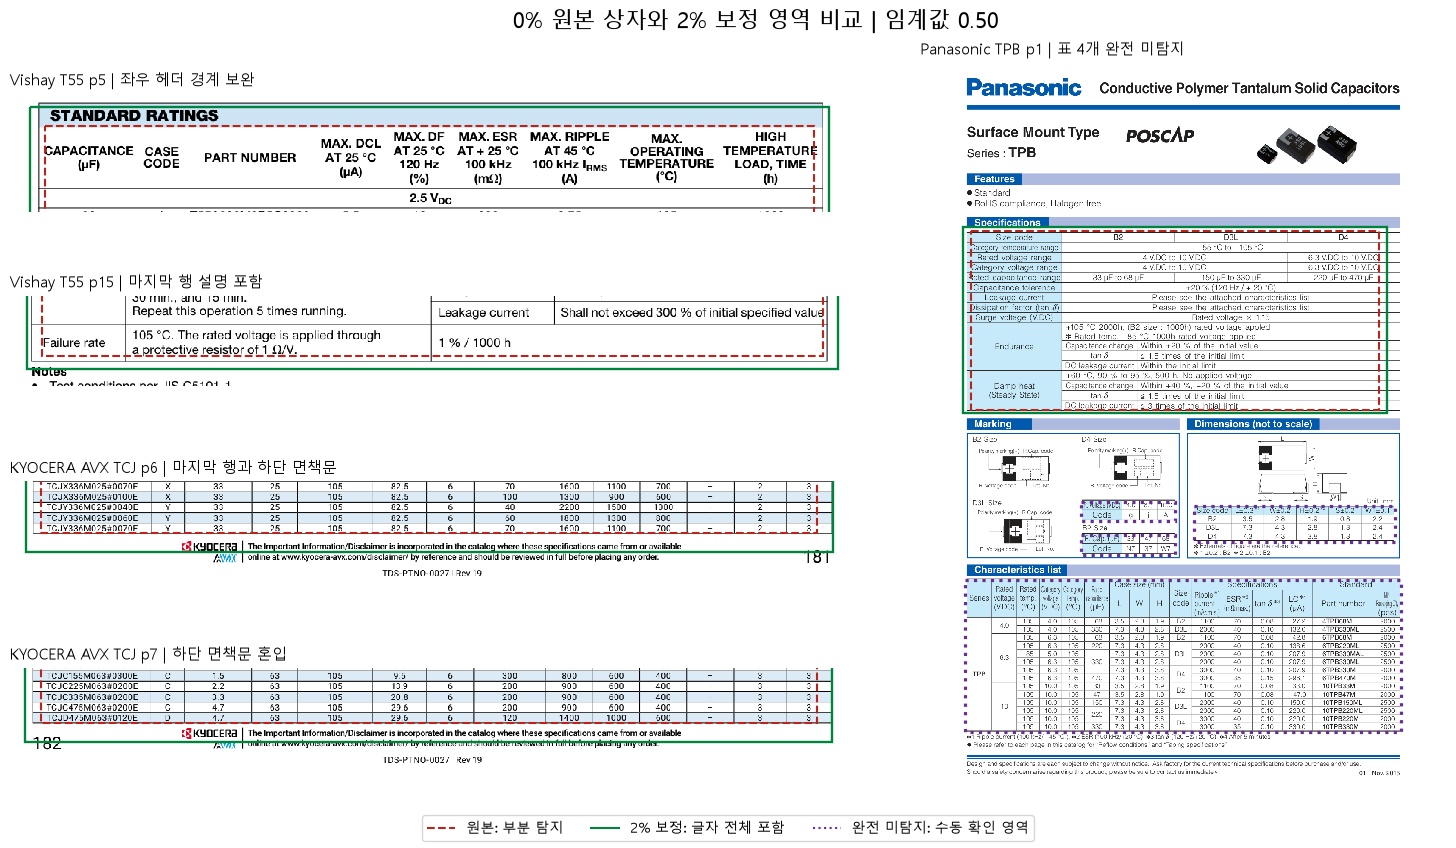

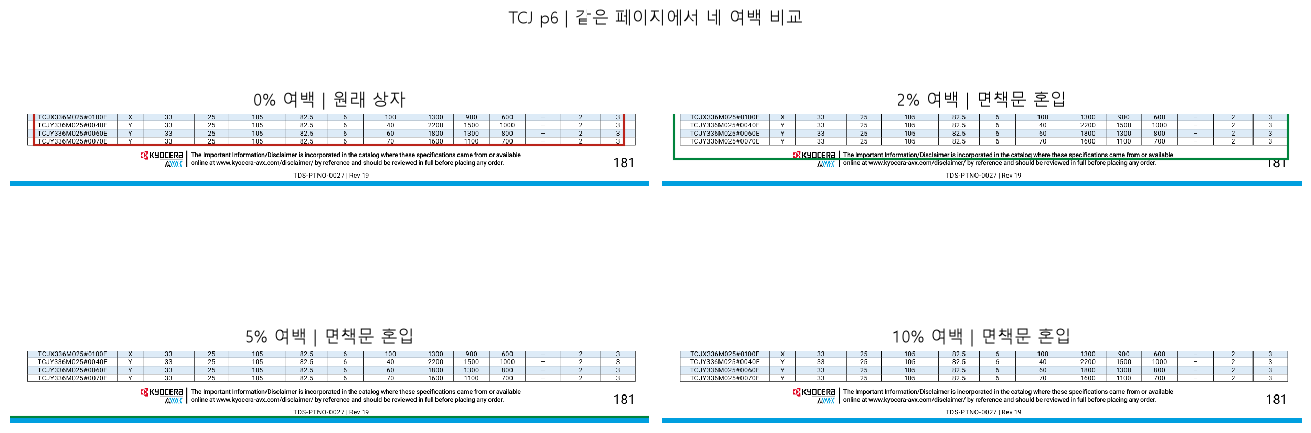

In [14]:
from matplotlib.lines import Line2D

def add_pdf_box(ax, bbox, color, style='-', linewidth=1.5):
    """PDF point 상자를 지정된 색과 선으로 표시함."""
    x0,y0,x1,y1 = bbox
    ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,
        edgecolor=color,linewidth=linewidth,linestyle=style))

def show_pdf_region(ax, key, window=None):
    """PDF point 축으로 원문 이미지와 동일한 위치를 표시함."""
    page = page_index[key]
    x0,y0,x1,y1 = page['page_metadata']['pdf_rect']
    ax.imshow(page['image'],extent=(x0,x1,y1,y0),interpolation='none')
    if window:
        ax.set_xlim(window[0],window[2])
        ax.set_ylim(window[3],window[1])
    ax.axis('off')

base = refinement.query('threshold == 0.5 and padding_ratio == 0')
examples_path = ROOT/'outputs/05_dl_detection_refinement_examples.png'
summary_path = ROOT/'outputs/05_dl_detection_refinement_summary.png'
refinement_csv_path = ROOT/'results/05_dl_detection_refinement.csv'
t55_key, tcj_key = ('vishay_t55',5),('kyocera_avx_tcj',6)
fig = plt.figure(figsize=(15,8.4),layout='constrained')
grid = fig.add_gridspec(4,2,width_ratios=[1.32,1])
axes = [fig.add_subplot(grid[i,0]) for i in range(4)] + [fig.add_subplot(grid[:,1])]
for ax,key,window,title in zip(axes,[t55_key,('vishay_t55',15),tcj_key,('kyocera_avx_tcj',7),tpb_key],
        [(35,79,576,155),(40,495,573,552),(12,710,597,776),(12,710,597,778),None],
        ['Vishay T55 p5 | 좌우 헤더 경계 보완','Vishay T55 p15 | 마지막 행 설명 포함',
         'KYOCERA AVX TCJ p6 | 마지막 행과 하단 면책문',
         'KYOCERA AVX TCJ p7 | 하단 면책문 혼입','Panasonic TPB p1 | 표 4개 완전 미탐지']):
    show_pdf_region(ax,key,window)
    row = recommended[(recommended.document_id==key[0]) & (recommended.page==key[1]) &
                      recommended.expanded_bbox_pdf.notna()].iloc[0]
    add_pdf_box(ax,json.loads(row.original_bbox_pdf),'#bb241b','--')
    add_pdf_box(ax,json.loads(row.expanded_bbox_pdf),'#00843d',linewidth=1.7)
    misses = recommended[(recommended.document_id==key[0]) & (recommended.page==key[1]) &
                         (recommended.detection_status=='undetected')]
    for missed in misses.itertuples():
        add_pdf_box(ax,json.loads(missed.reference_window_pdf),'#692c91',':',linewidth=2.3)
    ax.set_title(title,fontsize=11,loc='left')
fig.suptitle('0% 원본 상자와 2% 보정 영역 비교 | 임계값 0.50',fontsize=16)
legend = fig.legend(handles=[Line2D([],[],color='#bb241b',ls='--',label='원본: 부분 탐지'),
    Line2D([],[],color='#00843d',label='2% 보정: 글자 전체 포함'),
    Line2D([],[],color='#692c91',ls=':',label='완전 미탐지: 수동 확인 영역')],
    loc='outside lower center',ncol=3)
fig.savefig(examples_path,dpi=180)
plt.show()
plt.close(fig)

fig,axes = plt.subplots(2,2,figsize=(13,5),layout='constrained')
for ax,padding in zip(axes.flat,padding_ratios):
    show_pdf_region(ax,tcj_key,(12,718,597,784))
    row = refinement[(refinement.threshold==.50) & (refinement.padding_ratio==padding) &
                     (refinement.document_id==tcj_key[0]) & (refinement.page==tcj_key[1])].iloc[0]
    add_pdf_box(ax,json.loads(row.expanded_bbox_pdf),'#00843d' if padding else '#bb241b')
    ax.set_title(f'{padding:.0%} 여백 | ' + ('면책문 혼입' if padding else '원래 상자'))
fig.suptitle('TCJ p6 | 같은 페이지에서 네 여백 비교')
plt.show()
plt.close(fig)

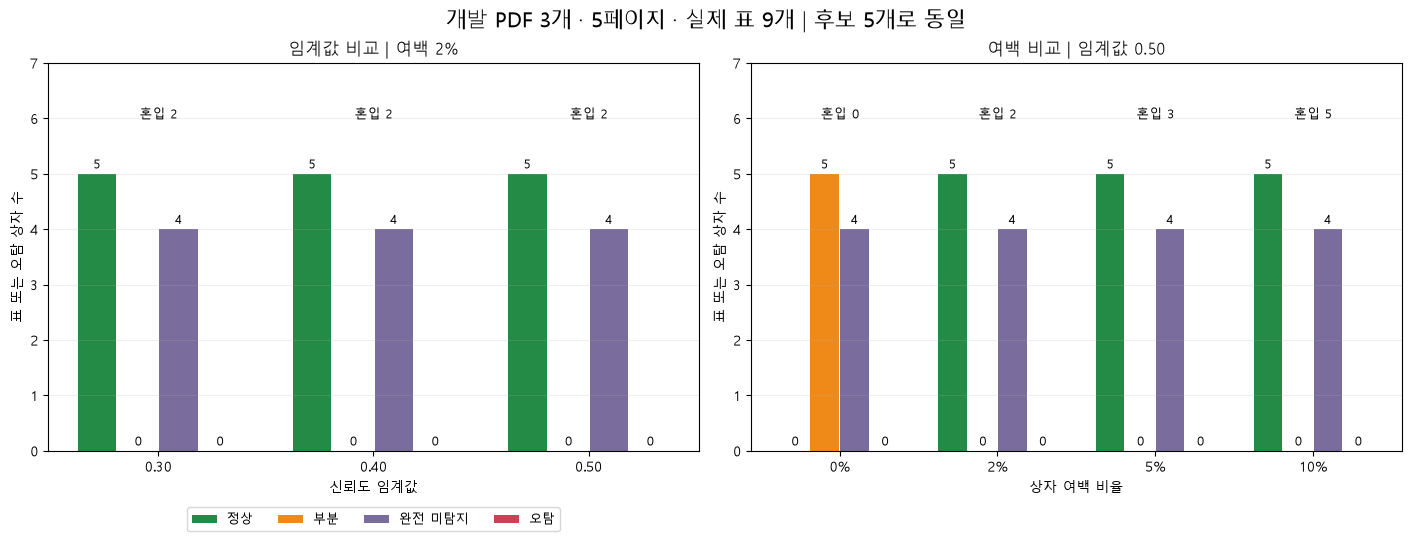

In [15]:
fig,axes = plt.subplots(1,2,figsize=(14,5.3),layout='constrained')
metric_labels = {'normal':'정상','partial':'부분','undetected':'완전 미탐지','false_positive':'오탐'}
colors = ['#238b45','#ef8a18','#7a6c9d','#cc4056']
for ax,values,title,xlabel in (
        (axes[0],condition_counts.xs(.02,level='padding_ratio'),'임계값 비교 | 여백 2%','신뢰도 임계값'),
        (axes[1],condition_counts.loc[.50],'여백 비교 | 임계값 0.50','상자 여백 비율')):
    pos = np.arange(len(values))
    for i,(metric,label) in enumerate(metric_labels.items()):
        bars = ax.bar(pos+(i-1.5)*.19,values[metric],width=.18,color=colors[i],label=label)
        ax.bar_label(bars,padding=2,fontsize=9)
    ax.set_xticks(pos,[f'{v:.2f}' if ax is axes[0] else f'{v:.0%}' for v in values.index])
    ax.set(xlabel=xlabel,ylabel='표 또는 오탐 상자 수',ylim=(0,7),title=title)
    ax.grid(axis='y',alpha=.2)
    for j,(_,row) in enumerate(values.iterrows()):
        ax.text(j,6.0,f"혼입 {int(row.unrelated)}",ha='center',fontsize=9)
axes[0].legend(ncol=4,fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.13))
fig.suptitle('개발 PDF 3개 · 5페이지 · 실제 표 9개 | 후보 5개로 동일',fontsize=15)
fig.savefig(summary_path,dpi=180)
plt.show()
plt.close(fig)

### 결론 및 한계
- 0.30·0.40·0.50 모두 후보 5개임. 추가 탐지·오탐 증가 없음
- 2%에서 기존 부분 탐지 5개 모두 글자 포함 기준으로 복구됨. 완전 미탐지 4개는 남음
- 여백 0·2·5·10%에서 관련 없는 본문 혼입은 각각 0·2·3·5개임. 2%의 정상 5개 중 3개는 혼입 없음. TCJ 2개에 하단 면책문 섞임
- 개발 후보는 임계값 0.50 + 여백 2%임. 동일 후보 수를 유지하며 시험 범위에서 가장 작은 복구 여백임
- 후보 영역 원문과 페이지 원문을 분리해 후속 검토에 전달 가능함. 면책문·다른 본문 필터링과 미탐지 보조 경로가 필요함
- 정상 5/9는 이번 5개 개발 페이지의 경계 포함 결과임. 셀 구조, 실제 P/N 규격 연결, LLM 추출, 평가 PDF 일반화 미검증임

In [16]:
assert len(refinement)==9*len(thresholds)*len(padding_ratios)
assert not refinement.duplicated(['document_id','page','table_id','threshold','padding_ratio']).any()
assert refinement.detection_status.eq('undetected').sum()==4*len(thresholds)*len(padding_ratios)
assert condition_counts.loc[(.50,.02),['normal','partial','undetected','false_positive','unrelated']].to_list()==[5,0,4,0,2]
assert all(p['page_text_pymupdf'] and p['page_text_pdfplumber'] for p in page_source.values())
assert all(p['region_text_pymupdf'] and p['region_text_pdfplumber'] for p in text_evidence.values())
assert expand_table_bbox([1,2,99,198],100,200,.1)==[0.,0.,100.,200.]
for row in refinement[refinement.expanded_bbox.notna()].itertuples():
    x0,y0,x1,y1 = json.loads(row.expanded_bbox)
    image = page_index[row.document_id,row.page]['image']
    assert 0<=x0<x1<=image.width and 0<=y0<y1<=image.height
for path in (examples_path,summary_path):
    with Image.open(path) as png:
        assert png.format=='PNG'
        png.verify()
refinement.to_csv(refinement_csv_path,index=False,encoding='utf-8-sig')
refinement_readback = pd.read_csv(refinement_csv_path)
assert len(refinement_readback)==len(refinement)
assert refinement_readback.loc[refinement_readback.detection_status=='undetected','expanded_bbox'].isna().all()
display({'status':'passed','rows':len(refinement_readback),'conditions':len(condition_counts),
    'candidate_model_runs':len(refinement_candidates),'recommended_threshold':recommended_threshold,
    'recommended_padding':recommended_padding,'normal':5,'partial':0,'undetected':4,'false_positive':0,
    'normal_with_unrelated_content':2})

{'status': 'passed',
 'rows': 108,
 'conditions': 12,
 'candidate_model_runs': 5,
 'recommended_threshold': 0.5,
 'recommended_padding': 0.02,
 'normal': 5,
 'partial': 0,
 'undetected': 4,
 'false_positive': 0,
 'normal_with_unrelated_content': 2}

## 구조 인식 검증
- 표 탐지는 페이지에서 표 위치를 제안함. 구조 인식은 잘라낸 표에서 행·열·헤더·병합 후보를 제안함. 원문 글자는 PDF에서 별도 확보함
- 기존 탐지 임계값 0.50과 여백 2% 유지함. Vishay T55 p5 규격표, KYOCERA AVX TCJ p6 규격표, Panasonic TPB p1 일반 규격표를 제조사별로 1개씩 선정함
- T55 p15와 TCJ p7은 중복 제조사 후보로 이번 구조 시험에서 제외함. TPB 완전 미탐지 4개는 추론하지 않고 CSV에 남김. 수동 crop 사용하지 않음
- 동일한 150 DPI 페이지의 원래 픽셀을 자름. 왼쪽·위는 내림, 오른쪽·아래는 올림하고 페이지 경계로 제한함
- 모델 전처리는 crop을 리사이즈함. 후처리 좌표는 crop 픽셀 크기로 복원함. 원시 상자를 유지하고 crop 경계로 제한한 후 crop 시작점을 더해 페이지 픽셀로 변환함. 원본 PDF point는 페이지 픽셀과 page.rect의 축별 비율로 환산함
- 표 구조 점수 임계값 0.50 고정함. 원시 객체에 NMS·구조 보정 적용하지 않음. 가중치 출처: https://huggingface.co/microsoft/table-transformer-structure-recognition

In [17]:
import re
from table_detection import (STRUCTURE_MODEL_NAME, STRUCTURE_MODEL_REVISION,
    load_structure_recognizer, crop_table_image, recognize_table_structure, structure_bbox_to_page)

structure_threshold = .50
structure_started = perf_counter()
structure_processor, structure_model, structure_device, structure_loading = load_structure_recognizer(
    cache_dir=ROOT/'.venv/model_cache',local_files_only=True)
structure_load_seconds = perf_counter()-structure_started
structure_checkpoint = Path(hf_hub_download(STRUCTURE_MODEL_NAME,'model.safetensors',
    revision=STRUCTURE_MODEL_REVISION, cache_dir=str(ROOT/'.venv/model_cache'), local_files_only=True))
structure_sha = hashlib.sha256(structure_checkpoint.read_bytes()).hexdigest()
assert structure_checkpoint.parent.name==STRUCTURE_MODEL_REVISION and not structure_model.training
assert all(k.endswith('.num_batches_tracked') for k in structure_loading.get('unexpected_keys',[]))
display({'model':STRUCTURE_MODEL_NAME,'revision':STRUCTURE_MODEL_REVISION,'sha256':structure_sha,
    'device':str(structure_device),'torch':torch.__version__,'transformers':metadata.version('transformers'),
    'threshold':structure_threshold,'load_seconds':structure_load_seconds,
    'labels':structure_model.config.id2label,
    'unexpected_keys':sorted(structure_loading.get('unexpected_keys',[]))})

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-structure-recognition
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'model': 'microsoft/table-transformer-structure-recognition',
 'revision': 'f4d4bdc85c3fe4b1fa49658882a5d38bbdd0f343',
 'sha256': 'f581da65a586591124cac9545b09b93e4e8bf28ce3a8357af6ac15ce94fce16b',
 'device': 'cpu',
 'torch': '2.15.0+cpu',
 'transformers': '5.22.2',
 'threshold': 0.5,
 'load_seconds': 0.2506781999982195,
 'labels': {0: 'table',
  1: 'table column',
  2: 'table row',
  3: 'table column header',
  4: 'table projected row header',
  5: 'table spanning cell'},
 'unexpected_keys': ['model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked',
  'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked',
  'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']}

In [18]:
structure_selection = {('vishay_t55',5):'standard_ratings',
                       ('kyocera_avx_tcj',6):'ratings_reference',
                       ('panasonic_tpb',1):'specifications'}
structure_input = pd.read_csv(ROOT/'results/05_dl_detection_refinement.csv')
structure_input = structure_input[(structure_input.threshold==.50) & (structure_input.padding_ratio==.02)]
structure_runs, structure_skips = {}, []
for source in structure_input.itertuples():
    key = (source.document_id,source.page)
    if source.detection_status=='undetected':
        structure_skips.append(source)
        continue
    if structure_selection.get(key)!=source.table_id:
        continue
    page_data = page_index[key]
    live = recommended[(recommended.document_id==key[0]) & (recommended.page==key[1]) &
                       (recommended.table_id==source.table_id)].iloc[0]
    assert np.allclose(json.loads(source.expanded_bbox),json.loads(live.expanded_bbox),atol=.05,rtol=0)
    assert source.source_pdf_sha256==pdf_hashes[key[0]] and source.model_revision==MODEL_REVISION
    crop, crop_box = crop_table_image(page_data['image'],json.loads(source.expanded_bbox))
    assert crop.size == (crop_box[2]-crop_box[0],crop_box[3]-crop_box[1])
    result = {'source':source,'crop':crop,'crop_box':crop_box,'objects':[],'timing':{},'error':None}
    try:
        objects,timing = recognize_table_structure(crop,structure_processor,structure_model,
            structure_device,threshold=structure_threshold)
        for obj in objects:
            obj['bbox_crop_clipped'],obj['bbox_page_pixels'],obj['bbox_pdf'] = structure_bbox_to_page(
                obj['bbox'],crop_box,page_data['page_metadata'])
        result.update(objects=objects,timing=timing)
    except (RuntimeError,ValueError) as error:
        result['error']=f'{type(error).__name__}: {error}'
        print('구조 추론 실패:',key,result['error'])
    structure_runs[key] = result
assert set(structure_runs)==set(structure_selection) and len(structure_skips)==4
display(pd.DataFrame([{'document_id':key[0],'page':key[1],'crop_pixels':run['crop'].size,
    'crop_box_page_pixels':run['crop_box'],'input_size':(run['timing'].get('model_input_width'),
    run['timing'].get('model_input_height')),'seconds':run['timing'].get('processing_seconds'),
    'objects':len(run['objects']),'error':run['error']} for key,run in structure_runs.items()]))

,document_id,page,crop_pixels,crop_box_page_pixels,input_size,seconds,objects,error
0,vishay_t55,5,"(1073, 1293)","(99, 182, 1172, 1475)","(800, 964)",0.870093,82,None
1,kyocera_avx_tcj,6,"(1171, 1395)","(48, 187, 1219, 1582)","(800, 953)",0.819706,107,None
2,panasonic_tpb,1,"(1002, 441)","(99, 387, 1101, 828)","(1000, 440)",0.486864,28,None


### 원문 대조 기준
- 물리 행·열 중심 위치를 원문에서 확인함. 정격표 본문 행은 원문 P/N 글자 중심, 표 제목을 뺀 열 헤더는 하나의 논리 행, 전압 구분 띠는 각각 한 행으로 셈
- TCJ의 100 kHz 그룹 헤더는 다단 형태이지만 행 집계에서는 제목 아래 전체 헤더를 한 논리 행으로 셈. 본문 기준 14열임
- TPB는 위쪽 Size code 표 기준 4열과 가로 구분선 기준 17행임. 하단의 병합 레이아웃 전체가 4열 격자라는 뜻은 아님
- 행·열 위치 일치는 한 원문 중심을 포함하는 예측이 하나이며 그 예측에 다른 원문 중심이 없는 경우임. 중복·합쳐진 예측을 제외함. 외곽선 일치·IoU·셀 구조 완전성을 뜻하지 않음
- 헤더 검증은 원문 헤더 단어 상자 전체가 예측 헤더 하나에 포함되는 조건임. 헤더 예측 유무와 완전 포함을 분리함
- P/N은 주문 코드를 해석하지 않고 보이는 원문을 사용함. 두 정격표에서 첫·중간·마지막 행 3개씩의 원문 값을 수동 대조함. 표본의 모든 선택 값이 각 교차 영역에서 유일하게 발견된 경우만 위치 연결 성공임
- P/N 행의 성공은 확인한 표본 중 하나 이상의 성공을 의미함. 표 전체에 일반화하지 않음

In [19]:
source_layout = {
    ('vishay_t55',5): dict(pattern=r'T55[A-Z][A-Z0-9]{12}', pn_band=(150,230,150,698),
        header_end=142, extra_rows=[120,147], columns=[85.7,132.6,189.6,254.5,298.5,343,395.4,457.9,524.8],
        specs={'capacitance':0,'esr':5}, pn_column=2,
        samples={'T55A226M2R5C0200':['22','200'],'T55B337M2R5C0025':['330','25'],
                 'T55X687M2R5C0005':['680','5']}),
    ('kyocera_avx_tcj',6): dict(pattern=r'TCJ[A-Z0-9#]{12,15}', pn_band=(35,105,138,748),
        header_end=138, extra_rows=[122,318,516],
        columns=[69.3,122.1,157.2,196.5,238.5,283.4,318.7,360.2,401.6,434.3,467.1,499.8,534.4,568.4],
        specs={'rated_voltage':3,'capacitance':2,'esr':7},pn_column=0,
        samples={'TCJD686M016#0050E':['16','68','50'],'TCJY476M020#0070E':['20','47','70'],
                 'TCJY336M025#0070E':['25','33','70']}),
    ('panasonic_tpb',1): dict(pattern=None,header_end=205,extra_rows=[
        199,210,221,233,244,255,267,278,289,305,322,333,344,355,366,378,390],
        columns=[105,223.8,351.4,478.9],specs={},samples={})
}

def axis_matches(anchors, objects, label, axis):
    """중심점과 예측 띠가 양방향으로 하나씩 대응할 때만 매칭함."""
    by_anchor = {a:[o for o in objects if o['label']==label and
        o['bbox_pdf'][axis]<=a<=o['bbox_pdf'][axis+2]] for a in anchors}
    return {a:group[0] for a,group in by_anchor.items() if len(group)==1 and
        sum(group[0]['bbox_pdf'][axis]<=b<=group[0]['bbox_pdf'][axis+2] for b in anchors)==1}

def link_sample(pn_word, expected, layout, words, row_map, column_map):
    """원문 토큰이 유일한 행·열 교차점에서 확인되는지 검사함."""
    x,y = word_center(pn_word)
    row = row_map.get(y)
    col = column_map.get(layout['columns'][layout['pn_column']])
    record = {'pn':pn_word[4],'pn_bbox_pdf':list(pn_word[:4]),'row_center_pdf':y,
        'unique_row':row is not None,'expected':dict(zip(layout['specs'],expected)),'verified_values':{}}
    if row is None:
        return {**record,'status':'ambiguous_row'}
    if col is None or not in_window(pn_word, (col['bbox_pdf'][0],row['bbox_pdf'][1],
                                              col['bbox_pdf'][2],row['bbox_pdf'][3])):
        return {**record,'status':'pn_column_mismatch'}
    for (field,i),value in zip(layout['specs'].items(),expected):
        spec_col = column_map.get(layout['columns'][i])
        if spec_col is None:
            continue
        box = [spec_col['bbox_pdf'][0],row['bbox_pdf'][1],spec_col['bbox_pdf'][2],row['bbox_pdf'][3]]
        cell_words = [w for w in words if in_window(w,box)]
        if len(cell_words)==1 and cell_words[0][4]==value and box[0] <= cell_words[0][0] <= cell_words[0][2] <= box[2]:
            record['verified_values'][field]={'text':value,'word_bbox_pdf':list(cell_words[0][:4]),
                'cell_bbox_pdf':box}
    return {**record,'status':'verified_sample' if len(record['verified_values'])==len(expected) else 'cell_mismatch'}

In [20]:
structure_records = []
for key,run in structure_runs.items():
    layout = source_layout[key]
    words = page_source[key]['page_words']
    objects = run['objects']
    source = run['source']
    class_counts = {label:sum(o['label']==label for o in objects)
        for label in structure_model.config.id2label.values()}
    pn_words = []
    if layout['pattern']:
        left,right,top,bottom = layout['pn_band']
        pn_words = [w for w in words if in_window(w,(left,top,right,bottom)) and re.fullmatch(layout['pattern'],w[4])]
    row_anchors = sorted(layout['extra_rows']+[word_center(w)[1] for w in pn_words])
    assert len(set(row_anchors))==len(row_anchors)
    row_map = axis_matches(row_anchors,objects,'table row',1)
    column_map = axis_matches(layout['columns'],objects,'table column',0)
    reference_window = json.loads(source.reference_window_pdf)
    header_words = [w for w in words if in_window(w,reference_window) and word_center(w)[1]<layout['header_end']]
    headers = [o for o in objects if o['label']=='table column header']
    header_missing = min((sum(not pymupdf.Rect(h['bbox_pdf']).contains(pymupdf.Rect(w[:4]))
        for w in header_words) for h in headers),default=len(header_words))
    samples=[]
    for pn,values in layout['samples'].items():
        pn_hits=[w for w in pn_words if w[4]==pn]
        assert len(pn_hits)==1
        samples.append(link_sample(pn_hits[0],values,layout,words,row_map,column_map))
    run.update(row_anchors=row_anchors,row_map=row_map,column_map=column_map,samples=samples)
    spec_columns = {field:column_map[layout['columns'][i]]['bbox_pdf'] for field,i in layout['specs'].items()
        if layout['columns'][i] in column_map}
    links=sum(s['status']=='verified_sample' for s in samples)
    sample_rows=sum(s['unique_row'] for s in samples)
    base = dict(document_id=key[0],page=key[1],table_id=source.table_id,
        input_type='automatic_detection',model_name=STRUCTURE_MODEL_NAME,model_revision=STRUCTURE_MODEL_REVISION,
        predicted_rows=class_counts['table row'],predicted_columns=class_counts['table column'],
        header_detected=bool(headers),header_verified=header_missing==0 and bool(header_words),
        pn_row_identified=bool(sample_rows) if samples else None,
        spec_column_identified=bool(spec_columns) if layout['specs'] else False,
        structure_status='inference_error' if run['error'] else
            ('partial_geometry' if header_missing or len(row_map)!=len(row_anchors) or
                len(column_map)!=len(layout['columns']) or class_counts['table column']!=len(layout['columns'])
                else 'geometry_matched'),
        processing_seconds=run['timing'].get('processing_seconds'),expected_rows=len(row_anchors),
        expected_columns=len(layout['columns']),matched_rows=len(row_map),matched_columns=len(column_map),
        matched_pn_rows=sum(word_center(w)[1] in row_map for w in pn_words) if pn_words else None,
        expected_pn_rows=len(pn_words) if pn_words else None,
        sample_count=len(samples),sample_rows_identified=sample_rows,sample_links_verified=links,
        class_counts=json.dumps(class_counts),pn_samples=json.dumps(samples,ensure_ascii=False),
        spec_columns_pdf=json.dumps(spec_columns),header_missing_words=header_missing,
        original_detection_bbox=source.original_bbox,expanded_detection_bbox=source.expanded_bbox,
        crop_bbox_page_pixels=json.dumps(run['crop_box']),crop_bbox_pdf=json.dumps(
            image_bbox_to_pdf(run['crop_box'],page_index[key]['page_metadata'])),
        objects_json=json.dumps(objects),detector_threshold=.50,padding_ratio=.02,
        structure_threshold=structure_threshold,source_pdf_sha256=source.source_pdf_sha256,
        structure_weight_sha256=structure_sha,manual_review_status='codex_source_reviewed',
        review_notes=run['error'] or {
            ('vishay_t55',5):'중복 행과 일부 경계 편차 있음. 오른쪽 헤더 글자 완전 포함 실패함. 2.5 V는 행 그룹 제목이므로 전압 열 연결 시험 제외함',
            ('kyocera_avx_tcj',6):'다단 헤더와 겹친 행 있음. DF 중심을 놓치고 오른쪽 MSL 열이 누락됨. spanning 후보는 정확한 셀 병합으로 확정하지 않음',
            ('panasonic_tpb',1):'첫 헤더 및 마지막 DC leakage current 행을 놓침. 추가 열이 B2 영역을 나눔. P/N은 별도 미탐지 표에 있고 규격은 고정 열 구조가 아님'
        }[key])
    structure_records.append(base)
for source in structure_skips:
    structure_records.append(dict(document_id=source.document_id,page=source.page,table_id=source.table_id,
        input_type='not_run_no_detection',model_name=STRUCTURE_MODEL_NAME,model_revision=STRUCTURE_MODEL_REVISION,
        structure_status='skipped_detection_miss',detector_threshold=.50,padding_ratio=.02,
        source_pdf_sha256=source.source_pdf_sha256,manual_review_status='codex_source_reviewed',
        review_notes='탐지 상자 없어 추론하지 않음. 페이지 원문 보조 경로 유지함'))
structure_results = pd.DataFrame(structure_records)
structure_evaluated = structure_results.query("input_type == 'automatic_detection'").copy()
display(structure_results[['document_id','page','table_id','structure_status','expected_rows','predicted_rows',
    'matched_rows','expected_columns','predicted_columns','matched_columns','header_detected',
    'header_verified','sample_count','sample_links_verified','processing_seconds']])
display(pd.DataFrame([{'document_id':key[0],'page':key[1],**sample}
    for key,run in structure_runs.items() for sample in run['samples']]))
for row in structure_evaluated.itertuples():
    print(row.document_id,row.review_notes,row.class_counts)

,document_id,page,table_id,structure_status,expected_rows,predicted_rows,matched_rows,expected_columns,predicted_columns,matched_columns,header_detected,header_verified,sample_count,sample_links_verified,processing_seconds
0,vishay_t55,5,standard_ratings,partial_geometry,58.0,70.0,44.0,9.0,9.0,9.0,True,False,3.0,2.0,0.870093
1,kyocera_avx_tcj,6,ratings_reference,partial_geometry,84.0,81.0,34.0,14.0,13.0,12.0,True,False,3.0,2.0,0.819706
2,panasonic_tpb,1,specifications,partial_geometry,17.0,15.0,15.0,4.0,5.0,4.0,False,False,0.0,0.0,0.486864
3,panasonic_tpb,1,dimensions,skipped_detection_miss,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,panasonic_tpb,1,voltage_code,skipped_detection_miss,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,panasonic_tpb,1,capacitance_code,skipped_detection_miss,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,panasonic_tpb,1,characteristics_list,skipped_detection_miss,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,document_id,page,pn,pn_bbox_pdf,row_center_pdf,unique_row,expected,verified_values,status
0,vishay_t55,5,T55A226M2R5C0200,"[151.139221, 153.910538, 228.075165, 161.890533]",157.900536,True,"{'capacitance': '22', 'esr': '200'}","{'capacitance': {'text': '22', 'word_bbox_pdf'...",verified_sample
1,vishay_t55,5,T55B337M2R5C0025,"[151.020309, 425.462097, 228.180603, 433.442108]",429.452103,False,"{'capacitance': '330', 'esr': '25'}",{},ambiguous_row
2,vishay_t55,5,T55X687M2R5C0005,"[151.320343, 688.134094, 227.880508, 696.114075]",692.124084,True,"{'capacitance': '680', 'esr': '5'}","{'capacitance': {'text': '680', 'word_bbox_pdf...",verified_sample
3,kyocera_avx_tcj,6,TCJD686M016#0050E,"[37.513599, 139.266479, 101.045784, 147.228485]",143.247482,True,"{'rated_voltage': '16', 'capacitance': '68', '...","{'rated_voltage': {'text': '16', 'word_bbox_pd...",verified_sample
4,kyocera_avx_tcj,6,TCJY476M020#0070E,"[37.901184, 438.882965, 100.676781, 446.844971]",442.863968,False,"{'rated_voltage': '20', 'capacitance': '47', '...",{},ambiguous_row
5,kyocera_avx_tcj,6,TCJY336M025#0070E,"[37.42157, 738.499695, 100.918968, 746.46167]",742.480682,True,"{'rated_voltage': '25', 'capacitance': '33', '...","{'rated_voltage': {'text': '25', 'word_bbox_pd...",verified_sample


vishay_t55 중복 행과 일부 경계 편차 있음. 오른쪽 헤더 글자 완전 포함 실패함. 2.5 V는 행 그룹 제목이므로 전압 열 연결 시험 제외함 {"table": 1, "table column": 9, "table row": 70, "table column header": 1, "table projected row header": 1, "table spanning cell": 0}
kyocera_avx_tcj 다단 헤더와 겹친 행 있음. DF 중심을 놓치고 오른쪽 MSL 열이 누락됨. spanning 후보는 정확한 셀 병합으로 확정하지 않음 {"table": 1, "table column": 13, "table row": 81, "table column header": 1, "table projected row header": 0, "table spanning cell": 11}
panasonic_tpb 첫 헤더 및 마지막 DC leakage current 행을 놓침. 추가 열이 B2 영역을 나눔. P/N은 별도 미탐지 표에 있고 규격은 고정 열 구조가 아님 {"table": 1, "table column": 5, "table row": 15, "table column header": 0, "table projected row header": 4, "table spanning cell": 3}


### 원문 위치 연결 해석
- T55의 정전용량과 ESR, TCJ의 정격전압·정전용량·ESR은 일부 표본에서 PDF 값과 구조 행·열 교차점이 일치함. 중복 행에 속한 표본은 실패 처리함
- T55 2.5 V는 전압 그룹 제목에서 보임. 이 값의 P/N 적용 범위를 구조 좌표만으로 확정하지 않음
- TPB의 일반 규격표에는 P/N 행이 없음. 치수표·코드표·P/N 특성표는 탐지 단계에서 누락되어 자동 구조 인식으로 복구하지 않음
- 2% 입력 자체에는 헤더와 본문 글자가 포함됐음. 구조 모델이 헤더·열·행을 놓친 경우와 원래 입력이 잘린 경우를 구분함. 다른 crop 여백에서의 구조 민감도는 비교하지 않음
- TCJ의 병합 후보와 TPB의 세로 병합 후보는 검토 대상으로 남김. rowspan/colspan, 완전한 셀 격자, 제조사별 주문 코드, LLM 추출은 검증하지 않음
- LLM 입력 후보로 원문 문자와 구조 좌표를 함께 전달할 수 있으나, 중복·누락 및 병합이 있는 행은 확정 근거로 사용하기 전에 재대조 필요함

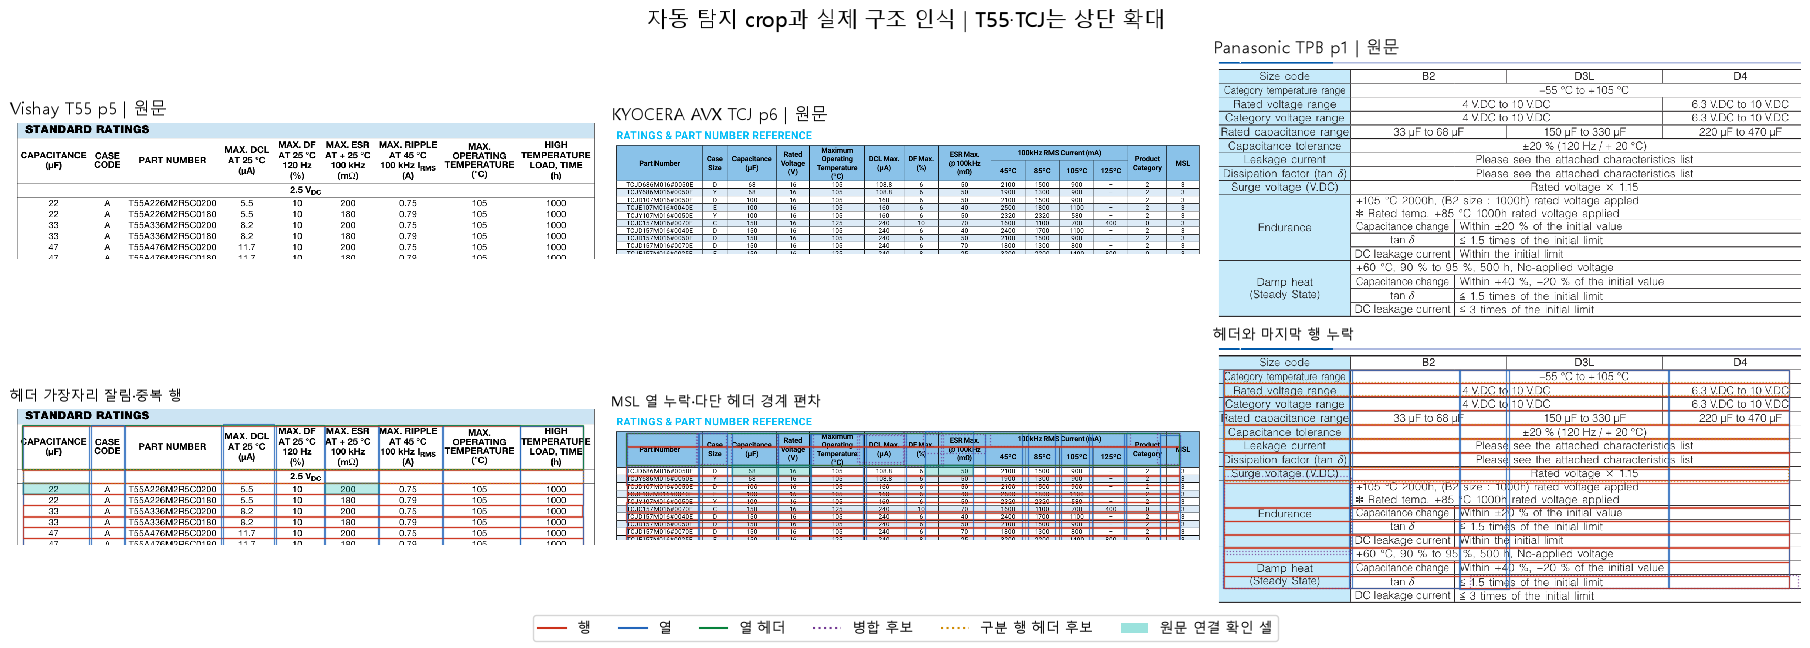

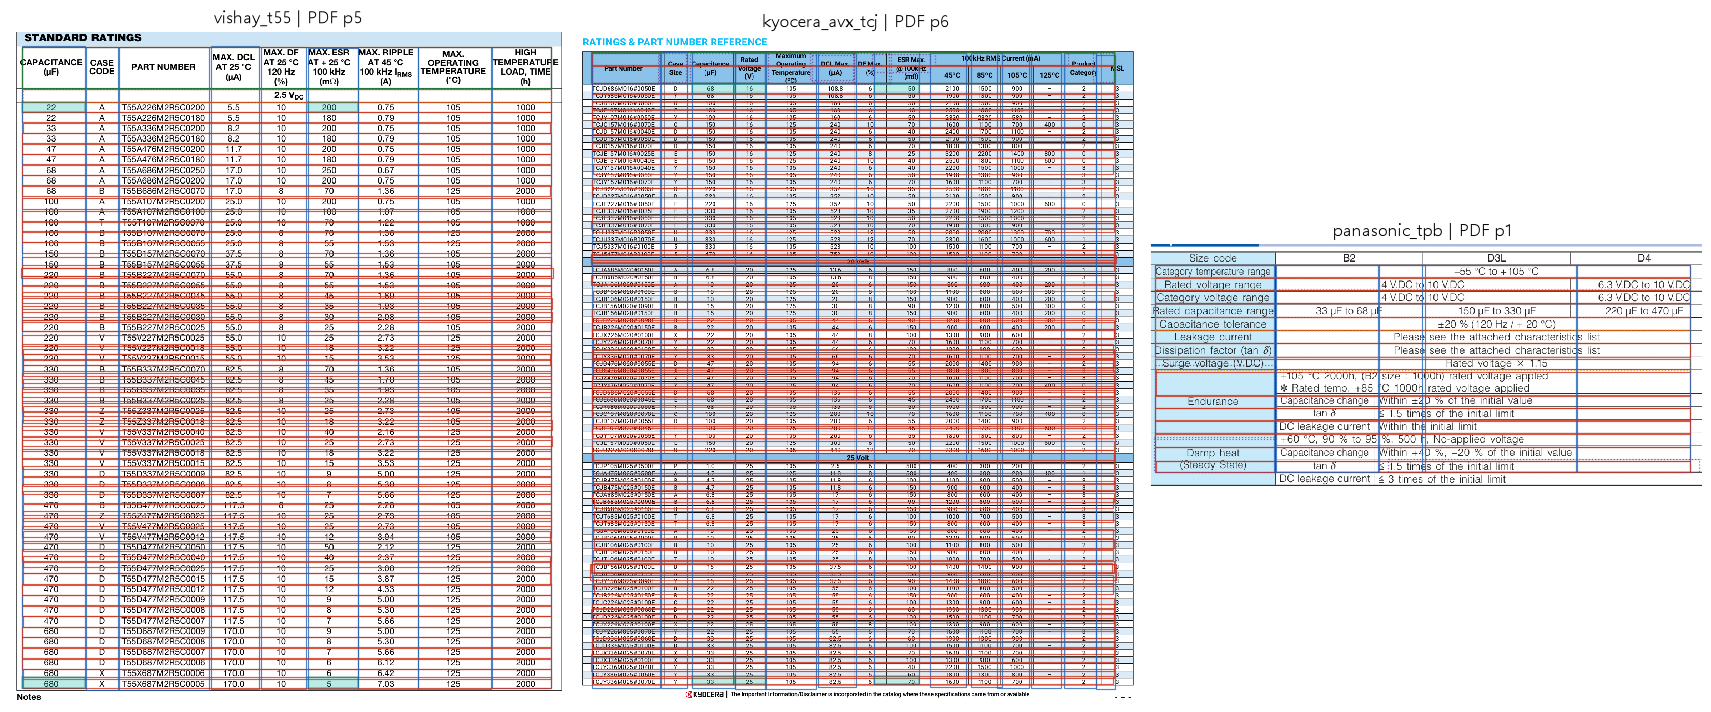

In [21]:
structure_example_path = ROOT/'outputs/05_dl_structure_examples.png'
structure_summary_path = ROOT/'outputs/05_dl_structure_summary.png'
structure_csv_path = ROOT/'results/05_dl_structure_recognition.csv'
structure_colors = {'table row':'#cc321b','table column':'#2366bb',
    'table column header':'#07823c','table spanning cell':'#733793',
    'table projected row header':'#d08a00'}

def draw_structure(ax, key, overlay=False, zoom=True):
    """같은 crop 위에 구조 객체와 검증된 교차 영역을 표시함."""
    run = structure_runs[key]
    image = run['crop']
    ax.imshow(image,interpolation='none')
    if overlay:
        for obj in run['objects']:
            label=obj['label']
            if label in structure_colors:
                x0,y0,x1,y1=obj['bbox_crop_clipped']
                ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,
                    edgecolor=structure_colors[label],alpha=.8,linewidth=.85,
                    linestyle=':' if label in ('table spanning cell','table projected row header') else '-'))
        meta=page_index[key]['page_metadata']
        sx,sy = meta['image_width']/meta['pdf_width_points'],meta['image_height']/meta['pdf_height_points']
        for sample in run['samples']:
            if sample['status']!='verified_sample':
                continue
            for item in sample['verified_values'].values():
                x0,y0,x1,y1=item['cell_bbox_pdf']
                dx,dy,_,_=run['crop_box']
                ax.add_patch(Rectangle((x0*sx-dx,y0*sy-dy),(x1-x0)*sx,(y1-y0)*sy,
                    facecolor='#07b8aa',edgecolor='#006e68',alpha=.28,linewidth=1.4))
    if zoom and key[0]!='panasonic_tpb':
        ax.set_ylim(248,-.5)
    ax.set_xlim(-.5,image.width-.5)
    ax.axis('off')

fig,axes = plt.subplots(2,3,figsize=(18,6.4),layout='constrained')
for j,(key,name) in enumerate(zip(structure_selection,
        ('Vishay T55 p5','KYOCERA AVX TCJ p6','Panasonic TPB p1'))):
    draw_structure(axes[0,j],key)
    draw_structure(axes[1,j],key,True)
    axes[0,j].set_title(name+' | 원문',loc='left')
    note = {'vishay_t55':'헤더 가장자리 잘림·중복 행',
            'kyocera_avx_tcj':'MSL 열 누락·다단 헤더 경계 편차',
            'panasonic_tpb':'헤더와 마지막 행 누락'}[key[0]]
    axes[1,j].set_title(note,loc='left',fontsize=10)
legend_labels = ['행','열','열 헤더','병합 후보','구분 행 헤더 후보']
fig.legend(handles=[Line2D([],[],color=color,label=label,ls=':' if i>=3 else '-')
    for i,(color,label) in enumerate(zip(structure_colors.values(),legend_labels))]+
    [Rectangle((0,0),1,1,facecolor='#07b8aa',alpha=.4,label='원문 연결 확인 셀')],
    loc='outside lower center',ncol=6)
fig.suptitle('자동 탐지 crop과 실제 구조 인식 | T55·TCJ는 상단 확대',fontsize=15)
fig.savefig(structure_example_path,dpi=180)
plt.show()
plt.close(fig)

fig,axes=plt.subplots(1,3,figsize=(17,8.5),layout='constrained')
for ax,key in zip(axes,structure_selection):
    draw_structure(ax,key,True,False)
    ax.set_title(f'{key[0]} | PDF p{key[1]}')
plt.show()
plt.close(fig)

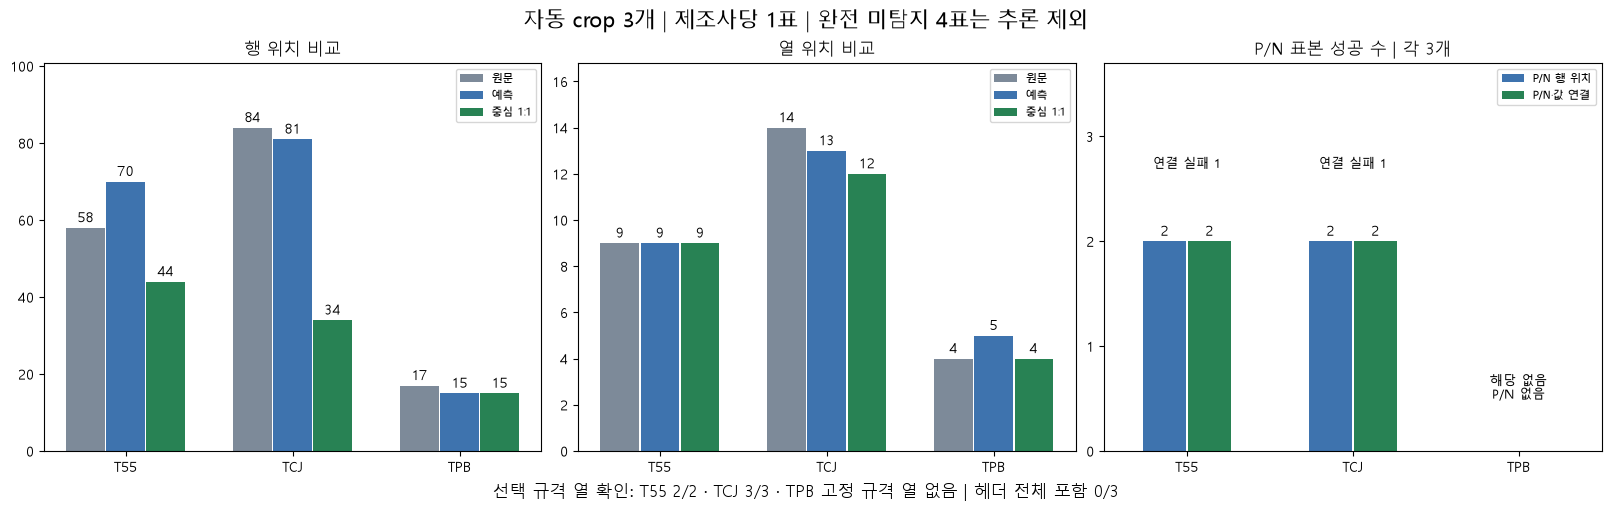

In [22]:
fig,axes = plt.subplots(1,3,figsize=(16,5),layout='constrained')
names = ['T55','TCJ','TPB']
x = np.arange(len(names))
for ax,axis,title in zip(axes[:2],('rows','columns'),('행 위치 비교','열 위치 비교')):
    for i,(prefix,label,color) in enumerate([('expected','원문','#7d8a99'),
            ('predicted','예측','#3e73ae'),('matched','중심 1:1','#288254')]):
        bars=ax.bar(x+(i-1)*.24,structure_evaluated[f'{prefix}_{axis}'],.23,label=label,color=color)
        ax.bar_label(bars,padding=2)
    ax.set_xticks(x,names)
    ax.set_ylim(0,structure_evaluated[[f'expected_{axis}',f'predicted_{axis}']].max().max()*1.2)
    ax.set_title(title)
    ax.legend(fontsize=8)
ax=axes[2]
for i,(column,label,color) in enumerate([('sample_rows_identified','P/N 행 위치','#3e73ae'),
        ('sample_links_verified','P/N·값 연결','#288254')]):
    bars=ax.bar(x[:2]+(i-.5)*.27,structure_evaluated[column].iloc[:2],.26,label=label,color=color)
    ax.bar_label(bars,padding=2)
ax.set_xticks(x,names)
ax.set_ylim(0,3.7)
ax.set_xlim(-.5,2.5)
ax.set_yticks([0,1,2,3])
ax.set_title('P/N 표본 성공 수 | 각 3개')
ax.text(2,.5,'해당 없음\nP/N 없음',ha='center',fontsize=9)
for i,row in enumerate(structure_evaluated.iloc[:2].itertuples()):
    ax.text(i,2.7,f'연결 실패 {int(row.sample_count-row.sample_links_verified)}',ha='center',fontsize=9)
ax.legend(fontsize=8)
fig.suptitle('자동 crop 3개 | 제조사당 1표 | 완전 미탐지 4표는 추론 제외',fontsize=15)
spec_caption = ' · '.join(f'{label} {len(json.loads(row.spec_columns_pdf))}/{len(source_layout[row.document_id,row.page]["specs"])}'
    for label,row in zip(names[:2],structure_evaluated.iloc[:2].itertuples()))
fig.supxlabel(f'선택 규격 열 확인: {spec_caption} · TPB 고정 규격 열 없음 | '
    f'헤더 전체 포함 {int(structure_evaluated.header_verified.sum())}/{len(structure_evaluated)}')
fig.savefig(structure_summary_path,dpi=180)
plt.show()
plt.close(fig)

In [23]:
structure_results.to_csv(structure_csv_path,index=False,encoding='utf-8-sig')
structure_readback=pd.read_csv(structure_csv_path)
assert len(structure_readback)==7 and not structure_readback.duplicated(['document_id','page','table_id']).any()
assert structure_readback.input_type.eq('not_run_no_detection').sum()==4
assert structure_readback.loc[structure_readback.input_type.eq('not_run_no_detection'),'predicted_rows'].isna().all()
for key,run in structure_runs.items():
    assert run['error'] is None,run['error']
    crop_box=run['crop_box']
    crop_page=page_index[key]
    for obj in run['objects']:
        local=obj['bbox_crop_clipped']
        pixel=obj['bbox_page_pixels']
        assert 0<=local[0]<local[2]<=run['crop'].width and 0<=local[1]<local[3]<=run['crop'].height
        assert np.allclose(np.array(pixel)-np.tile(crop_box[:2],2),local,atol=1e-8,rtol=0)
        pdf=obj['bbox_pdf']
        meta=crop_page['page_metadata']
        px=np.array(pdf)*np.tile([meta['image_width']/meta['pdf_width_points'],
                                  meta['image_height']/meta['pdf_height_points']],2)
        assert np.allclose(px,pixel,atol=1e-7,rtol=0)
for path in (structure_example_path,structure_summary_path):
    with Image.open(path) as png:
        assert png.format=='PNG'
        png.verify()
assert all(path.suffix.lower()=='.png' for path in (ROOT/'outputs').rglob('*') if path.is_file())
display({'status':'passed','automatic_tables':len(structure_evaluated),'skipped_detection_misses':len(structure_skips),
    'sample_links_verified':int(structure_evaluated.sample_links_verified.sum()),
    'seconds_total':float(structure_evaluated.processing_seconds.sum()),
    'seconds_per_table':float(structure_evaluated.processing_seconds.mean()),
    'detector_regression':'기존 결과 좌표·점수 일치 확인함'})

{'status': 'passed',
 'automatic_tables': 3,
 'skipped_detection_misses': 4,
 'sample_links_verified': 4,
 'seconds_total': 2.176662700017914,
 'seconds_per_table': 0.7255542333393047,
 'detector_regression': '기존 결과 좌표·점수 일치 확인함'}